In [1]:
#from google.colab import drive
#drive.mount("/content/drive")

# Corrección de errores de secuenciación con GENERanno

Detección y corrección de sustituciones en secuencias codificantes de *E. coli* (entrenamiento y evaluación) y *H. volcanii* (prueba fuera de dominio), tratando el ADN como un lenguaje.

## 0. Configuración

In [2]:
# Install dependencies (transformers 4.57.3: runs GENERanno without patches and its tokenizers has wheels for Python 3.13+) and MMseqs2; torch is left out because Colab ships one built for its CUDA (uncomment the next line to install it locally)
# %pip install -q torch
%pip install -q transformers==4.57.3 peft==0.13.2 matplotlib pandas seaborn scikit-learn biopython wordcloud
!wget -q https://mmseqs.com/latest/mmseqs-linux-avx2.tar.gz
!tar xzf mmseqs-linux-avx2.tar.gz

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Imports (gc is aliased because the name gc is used by the GC-content function)
import re
import os
import json
import math
import time
import copy
import gc as pygc
from collections import Counter
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from wordcloud import WordCloud
from Bio.Seq import Seq
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import average_precision_score

import torch
from torch import nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForMaskedLM, AutoTokenizer, get_linear_schedule_with_warmup, set_seed
from peft import LoraConfig, get_peft_model

/home/dani22002/Documents/nlp/proyecto/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Root folder of the input genomes, the trained models and the saved results (e.g. the n-gram search table); on Colab point it to Drive (e.g. "/content/drive/MyDrive/nlp") so they survive the session
SAVE_ROOT = "."

## 1. Lectura y análisis de los datos (Entrega 1)

### 1.1 Lectura y limpieza

In [5]:
# Valid start codons (translation table 11) and stop codons
CODONES_INICIO = {"ATG", "GTG", "TTG", "CTG", "ATT", "ATC", "ATA"}
CODONES_PARADA = {"TAA", "TAG", "TGA"}

In [6]:
# Header fields found in the E. coli K-12 MG1655 (GCF_000005845.2) and H. volcanii DS2 (GCF_000025685.1) files: header key -> column name
CAMPOS_ENCABEZADO = {
    "gene": "gen",
    "locus_tag": "locus_tag",
    "db_xref": "db_xref",
    "protein": "proteina",
    "protein_id": "protein_id",
    "location": "ubicacion",
    "gbkey": "gbkey",
    "pseudo": "pseudo",
    "partial": "parcial",
    "exception": "excepcion",
    "transl_except": "transl_except",
}

In [7]:
def leer_fasta(ruta):
    """
    Reads a FASTA file into (header, sequence) pairs.

    Sequence lines are joined and uppercased; blank lines are ignored.

    Parameters
    ----------
    ruta : str
        Path to the FASTA file.

    Returns
    -------
    registros : list of tuple of (str, str)
        One (header, sequence) pair per record, with the header without the leading ">".
    """
    registros, encabezado, partes = [], None, []
    with open(ruta) as f:
        for linea in f:
            linea = linea.strip()
            if linea.startswith(">"):
                if encabezado is not None:
                    registros.append((encabezado, "".join(partes)))
                encabezado, partes = linea[1:], []
            elif linea:
                partes.append(linea.upper())
    if encabezado is not None:
        registros.append((encabezado, "".join(partes)))
    return registros

In [8]:
def campo(encabezado, nombre):
    """
    Extracts the value of a [name=value] field from a FASTA header.

    According to the NCBI README, some values (e.g. protein names) may contain unescaped
    brackets, so the value ends only where the next field starts ("] [") or at the end
    of the line.

    Parameters
    ----------
    encabezado : str
        FASTA header line.
    nombre : str
        Field name, e.g. "gene" or "locus_tag".

    Returns
    -------
    valor : str or None
        Field value, or None if the header does not contain the field.
    """
    m = re.search(rf"\[{nombre}=(.*?)\](?= \[|$)", encabezado)
    return m.group(1) if m else None

In [9]:
def gc(seq):
    """
    Computes the GC content of a sequence.

    Parameters
    ----------
    seq : str
        Nucleotide sequence.

    Returns
    -------
    gc : float
        Fraction of G and C nucleotides; 0.0 for an empty sequence.
    """
    return (seq.count("G") + seq.count("C")) / len(seq) if seq else 0.0

In [10]:
def construir_tabla(registros):
    """
    Builds a table with one row per coding sequence and its descriptive variables.

    Each row holds the identifier, the replicon, the header fields in CAMPOS_ENCABEZADO
    (None when missing), and derived variables: strand, length, number of codons, overall
    GC content and GC content at each codon position, start and stop codons, and the
    sequence itself. Repeated sequences are flagged, keeping the first occurrence.

    Parameters
    ----------
    registros : list of tuple of (str, str)
        (header, sequence) pairs as returned by leer_fasta.

    Returns
    -------
    df : pandas.DataFrame
        One row per record, plus the boolean column "duplicado".
    """
    filas = []
    for enc, seq in registros:
        identificador = enc.split()[0]
        fila = {
            "id": identificador,
            "replicon": identificador.split("|")[1].split("_cds")[0],
        }
        for clave, columna in CAMPOS_ENCABEZADO.items():
            fila[columna] = campo(enc, clave)
        fila.update({
            "hebra": "-" if (fila["ubicacion"] or "").startswith("complement") else "+",
            "longitud": len(seq),
            "num_codones": len(seq) // 3,
            "gc": gc(seq),
            "gc_pos1": gc(seq[0::3]),
            "gc_pos2": gc(seq[1::3]),
            "gc_pos3": gc(seq[2::3]),
            "codon_inicio": seq[:3],
            "codon_parada": seq[-3:],
            "secuencia": seq,
        })
        filas.append(fila)
    df = pd.DataFrame(filas)
    df["duplicado"] = df.duplicated("secuencia", keep="first")
    return df

In [11]:
def filtrar(df):
    """
    Removes the sequences that are not suitable for training and reports each filter.

    The filters are applied in order: pseudogenes, partial CDS, translation exceptions,
    non-ACGT characters, length not divisible by 3, invalid start codon, invalid stop
    codon and duplicated sequence. For each filter it prints how many genes it discards
    (counting each gene only in the first filter that removes it) and how many genes meet
    the condition independently of the other filters.

    Parameters
    ----------
    df : pandas.DataFrame
        Table as returned by construir_tabla.

    Returns
    -------
    df_limpio : pandas.DataFrame
        Copy of the rows that pass every filter.
    """
    filtros = {
        "pseudogen": df["pseudo"].isna(),
        "CDS parcial": df["parcial"].isna(),
        "excepción de traducción": df["excepcion"].isna() & df["transl_except"].isna(),
        "caracteres no ACGT": df["secuencia"].str.fullmatch("[ACGT]+"),
        "longitud no múltiplo de 3": df["longitud"] % 3 == 0,
        "codón de inicio inválido": df["codon_inicio"].isin(CODONES_INICIO),
        "codón de parada inválido": df["codon_parada"].isin(CODONES_PARADA),
        "secuencia duplicada": ~df["duplicado"],
    }
    mascara = pd.Series(True, index=df.index)
    print("\nGenes descartados por cada filtro y total de genes con esas condiciones (aplicados en orden):")
    for nombre, cond in filtros.items():
        indices = pd.Series(True, index=df.index)
        descartados = (mascara & ~cond).sum()
        total_condicion = (indices & ~cond).sum()
        print(f"  {nombre:<28} {descartados:>5} ---- Total: {total_condicion}")
        mascara &= cond
    return df[mascara].copy()

In [12]:
def guardar_fasta(df, ruta):
    """
    Writes the sequences of a table to a FASTA file.

    Each header has the form ">id locus_tag=..." and sequences are wrapped at 80
    characters per line.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the columns "id", "locus_tag" and "secuencia".
    ruta : str
        Output path.
    """
    with open(ruta, "w") as f:
        for _, fila in df.iterrows():
            f.write(f">{fila['id']} locus_tag={fila['locus_tag']}\n")
            seq = fila["secuencia"]
            for i in range(0, len(seq), 80):
                f.write(seq[i:i + 80] + "\n")

In [13]:
# Paths to the RefSeq CDS files, inside SAVE_ROOT
ruta_arqueas = os.path.join(SAVE_ROOT, "arqueas.fna")
ruta_ecoli = os.path.join(SAVE_ROOT, "ecoli.fna")

In [14]:
# Read both genomes into tables
df_arqueas = construir_tabla(leer_fasta(ruta_arqueas))
df_ecoli = construir_tabla(leer_fasta(ruta_ecoli))
print(f"Genes arqueas leídos: {len(df_arqueas)}")
print(f"Genes E. coli leídos: {len(df_ecoli)}")

Genes arqueas leídos: 4017
Genes E. coli leídos: 4318


In [15]:
# Inspect the archaea table
df_arqueas.head()

,id,replicon,gen,locus_tag,db_xref,proteina,protein_id,ubicacion,gbkey,pseudo,...,longitud,num_codones,gc,gc_pos1,gc_pos2,gc_pos3,codon_inicio,codon_parada,secuencia,duplicado
0,lcl|NC_013967.1_cds_WP_004044954.1_1,NC_013967.1,NaN,HVO_RS04710,GeneID:8926884,Cdc6/Cdc18 family protein,WP_004044954.1,258..1952,CDS,NaN,...,1695,565,0.648968,0.667257,0.378761,0.900885,ATG,TGA,ATGGACGAGGAAGAGAATCCGCGAGGCGGCGCACGAGGGGAAGCCG...,False
1,lcl|NC_013967.1_cds_WP_004044955.1_2,NC_013967.1,NaN,HVO_RS04715,GeneID:8926122,S26 family signal peptidase,WP_004044955.1,complement(2000..2797),CDS,NaN,...,798,266,0.690476,0.684211,0.526316,0.860902,GTG,TGA,GTGCTAACTCGGCTTCGGACGGCAGAGGAGGGGCCGCTTCTGTTCG...,False
2,lcl|NC_013967.1_cds_WP_004044956.1_3,NC_013967.1,NaN,HVO_RS04720,GeneID:8924320,DNA-directed DNA polymerase II small subunit,WP_004044956.1,2942..4543,CDS,NaN,...,1602,534,0.667291,0.685393,0.425094,0.891386,GTG,TGA,GTGCCACTGGAGACGCCGGCGCGCATCGTCCGGACGCTCGTCGGTC...,False
3,lcl|NC_013967.1_cds_WP_004044957.1_4,NC_013967.1,NaN,HVO_RS04725,GeneID:8924855,oxidoreductase,WP_004044957.1,4686..5813,CDS,NaN,...,1128,376,0.708333,0.723404,0.473404,0.928191,ATG,TGA,ATGACCGACGACGCGCTGTTCGACGCGACGAGCCTGAACGACCTGT...,False
4,lcl|NC_013967.1_cds_WP_013035623.1_5,NC_013967.1,NaN,HVO_RS04730,GeneID:8926047,ZIP family metal transporter,WP_013035623.1,complement(5936..6745),CDS,NaN,...,810,270,0.680247,0.670370,0.433333,0.937037,GTG,TAG,GTGACGGCGGTCGAAGAGCTGTTCGTCTCGCTCGCCGGCTCGAACC...,False


In [16]:
# Columns of the table
df_ecoli.columns

Index(['id', 'replicon', 'gen', 'locus_tag', 'db_xref', 'proteina',
       'protein_id', 'ubicacion', 'gbkey', 'pseudo', 'parcial', 'excepcion',
       'transl_except', 'hebra', 'longitud', 'num_codones', 'gc', 'gc_pos1',
       'gc_pos2', 'gc_pos3', 'codon_inicio', 'codon_parada', 'secuencia',
       'duplicado'],
      dtype='str')

In [17]:
# Total number of nucleotides in E. coli
sum(df_ecoli["secuencia"].apply(lambda x: len(x)))

4026887

In [18]:
# Total number of nucleotides in archaea
sum(df_arqueas["secuencia"].apply(lambda x: len(x)))

3465867

In [19]:
# Apply the filters to both genomes
df_ecoli_limpio = filtrar(df_ecoli)
df_arqueas_limpio = filtrar(df_arqueas)


Genes descartados por cada filtro y total de genes con esas condiciones (aplicados en orden):
  pseudogen                       18 ---- Total: 18
  CDS parcial                      0 ---- Total: 0
  excepción de traducción          6 ---- Total: 6
  caracteres no ACGT               0 ---- Total: 0
  longitud no múltiplo de 3        0 ---- Total: 1
  codón de inicio inválido         0 ---- Total: 1
  codón de parada inválido         0 ---- Total: 2
  secuencia duplicada             39 ---- Total: 39

Genes descartados por cada filtro y total de genes con esas condiciones (aplicados en orden):
  pseudogen                      120 ---- Total: 120
  CDS parcial                      0 ---- Total: 65
  excepción de traducción          2 ---- Total: 2
  caracteres no ACGT               0 ---- Total: 0
  longitud no múltiplo de 3        0 ---- Total: 51
  codón de inicio inválido         0 ---- Total: 35
  codón de parada inválido         0 ---- Total: 28
  secuencia duplicada             22 

### 1.2 Análisis exploratorio

#### Frecuencia de nucleótidos

In [20]:
# Count the nucleotides of each genome
all_nucleotides_ecoli = "".join(df_ecoli_limpio["secuencia"].tolist())
ecoli_nucleotide_counter = Counter(all_nucleotides_ecoli)

all_nucleotides_arqueas = "".join(df_arqueas_limpio["secuencia"].tolist())
arqueas_nucleotide_counter = Counter(all_nucleotides_arqueas)

In [21]:
def plot_nucleotides(counter, title, ax=None, x_label = "Nucleótido"):
  """
  Plots the percentage of each symbol in a counter as a bar chart.

  Bars are sorted alphabetically and labeled with their percentage.

  Parameters
  ----------
  counter : collections.Counter
      Counts per symbol (nucleotides or codons).
  title : str
      Plot title.
  ax : matplotlib.axes.Axes, optional
      Axes to draw on; a new figure is created if None.
  x_label : str, optional
      Label of the x axis.

  Returns
  -------
  fig : matplotlib.figure.Figure
      Figure that contains the plot.
  ax : matplotlib.axes.Axes
      Axes with the plot.
  """
  nucleotides_series = pd.Series(counter)
  total_nucleotides = nucleotides_series.sum()
  percentages = (nucleotides_series / total_nucleotides) * 100

  if ax is None:
      fig, ax = plt.subplots(figsize=(8, 6))
  else:
      fig = ax.figure

  percentages = percentages.sort_index()

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)

  ax.set_title(title)
  ax.set_xlabel(x_label)
  ax.set_ylabel('Porcentaje')
  ax.set_ylim(0, max(percentages.values) * 1.1)

  for index, value in enumerate(percentages.values):
      ax.text(index, value + 0.5, f'{value:.2f}%', color='black', ha='center')

  return fig, ax

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


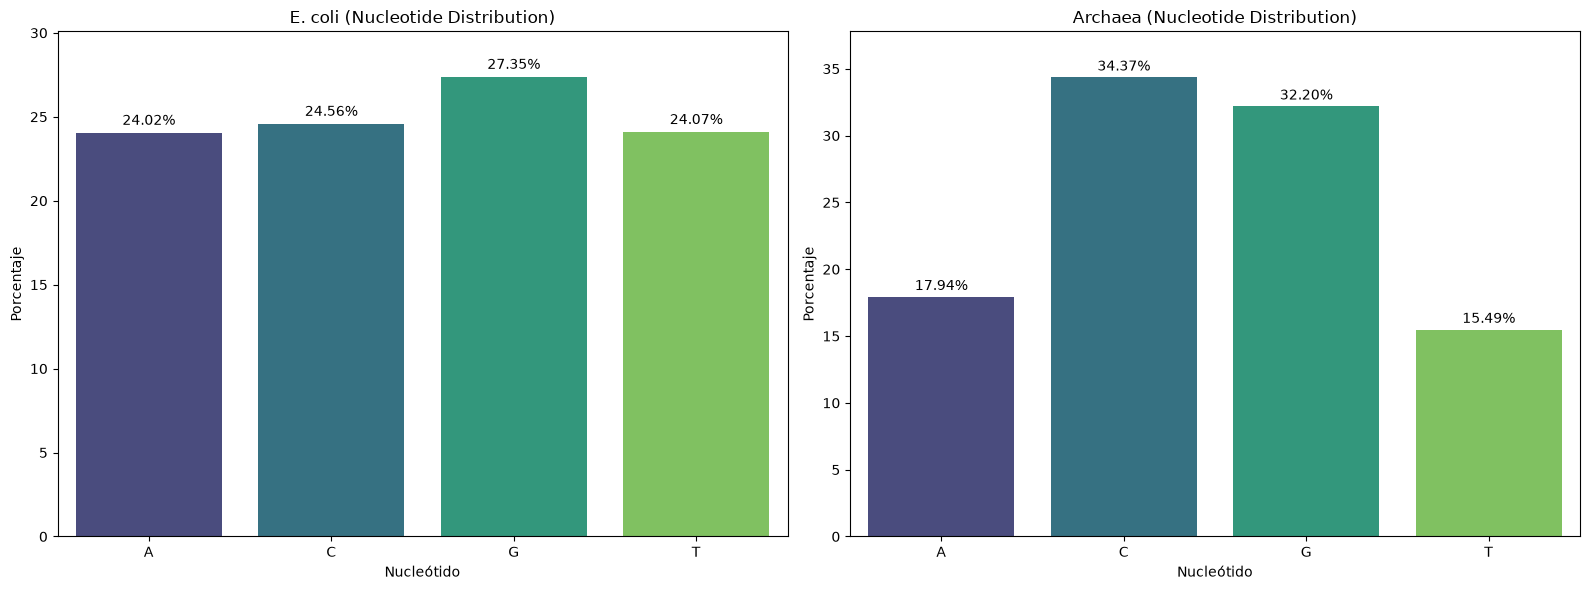

In [22]:
# Nucleotide distribution of both genomes side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_nucleotides(ecoli_nucleotide_counter, 'E. coli (Nucleotide Distribution)', ax=axes[0])
plot_nucleotides(arqueas_nucleotide_counter, 'Archaea (Nucleotide Distribution)', ax=axes[1])

plt.tight_layout()
plt.show()

#### Frecuencia por posición en el codón

In [23]:
def calculate_freq_position(all_nucleotides):
  """
  Plots the nucleotide distribution at each of the three codon positions.

  Parameters
  ----------
  all_nucleotides : str
      Concatenation of in-frame coding sequences, so that every third nucleotide
      shares the same codon position.
  """

  fig, axes = plt.subplots(1, 3, figsize=(16, 6))

  first_pos_freqs = Counter(all_nucleotides[0::3])
  second_pos_freqs = Counter(all_nucleotides[1::3])
  third_pos_freqs = Counter(all_nucleotides[2::3])

  plot_nucleotides(first_pos_freqs, "Primera posición", axes[0])
  plot_nucleotides(second_pos_freqs, "Segunda posición", axes[1])
  plot_nucleotides(third_pos_freqs, "Tercera posición", axes[2])

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


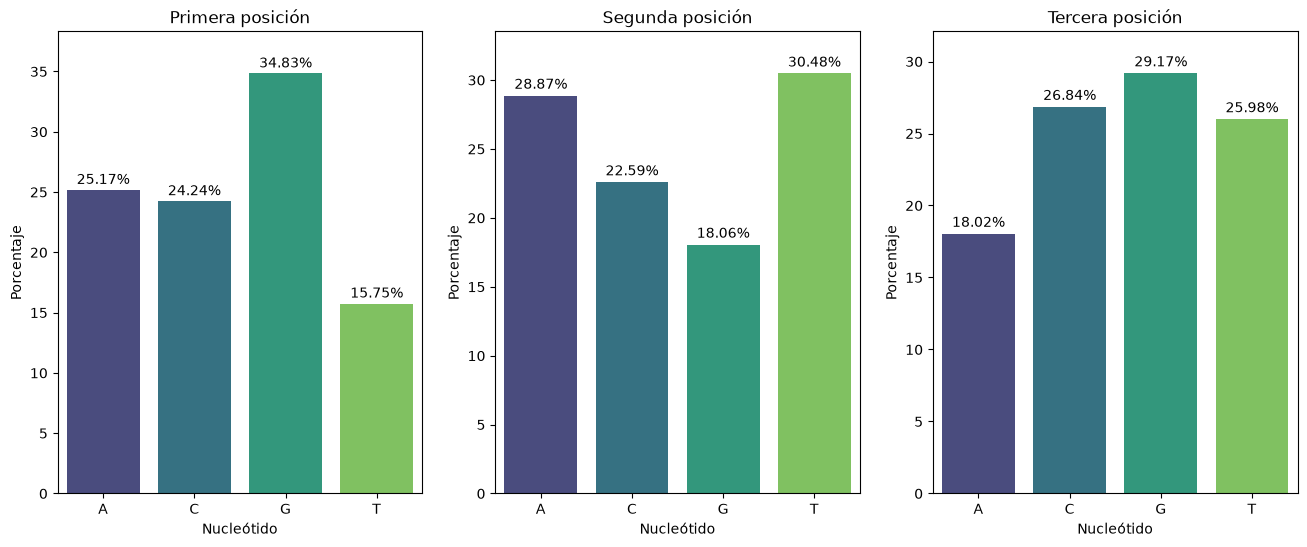

In [24]:
# Distribution per codon position in E. coli
calculate_freq_position(all_nucleotides_ecoli)

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


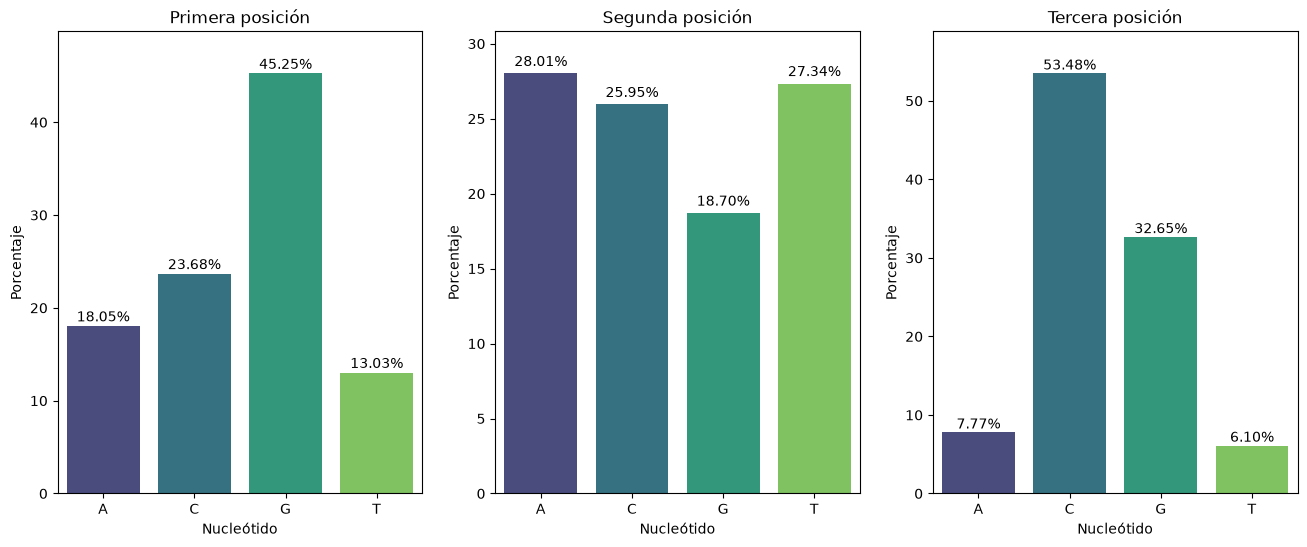

In [25]:
# Distribution per codon position in archaea
calculate_freq_position(all_nucleotides_arqueas)

#### Frecuencia de codones

In [26]:
def plot_codon_freq(all_nucleotides, title='Distribución de Codones (10 más frecuentes)'):
  """
  Plots a word cloud with the 10 most frequent codons.

  Parameters
  ----------
  all_nucleotides : str
      Concatenation of in-frame coding sequences; codons are read every 3 nucleotides.
  title : str, optional
      Plot title.
  """
  codon_counter = Counter(all_nucleotides[i:i+3] for i in range(0, len(all_nucleotides), 3))

  top_10_codons = dict(codon_counter.most_common(10))

  wordcloud = WordCloud(width=1600, height=800, background_color='white').generate_from_frequencies(top_10_codons)

  plt.figure(figsize=(15, 7))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.axis('off')
  plt.title(title)
  plt.show()

In [27]:
def plot_codon_freq_bar_chart(all_nucleotides, title='Distribución de Codones'):
  """
  Plots the percentage of every codon as a bar chart.

  Parameters
  ----------
  all_nucleotides : str
      Concatenation of in-frame coding sequences; codons are read every 3 nucleotides.
  title : str, optional
      Plot title.
  """
  fig, ax = plt.subplots(figsize=(30, 6))
  codon_counter = Counter(all_nucleotides[i:i+3] for i in range(0, len(all_nucleotides), 3))
  plot_nucleotides(codon_counter, title, ax=ax, x_label='Codón')
  plt.tight_layout()
  plt.show()

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


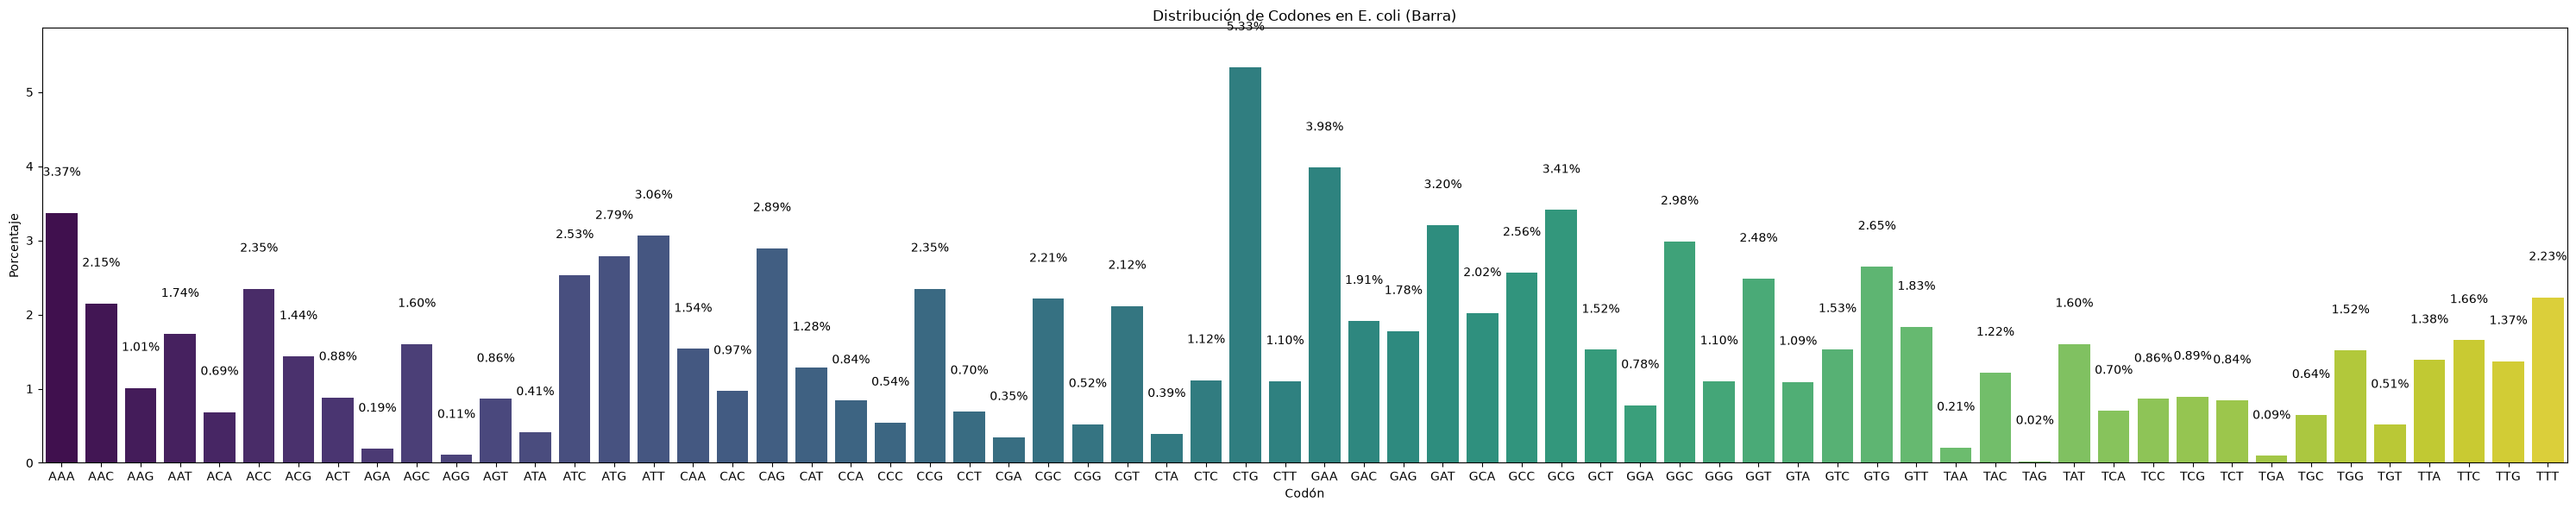

In [28]:
# Codon frequencies in E. coli
plot_codon_freq_bar_chart(all_nucleotides_ecoli, title='Distribución de Codones en E. coli (Barra)')

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


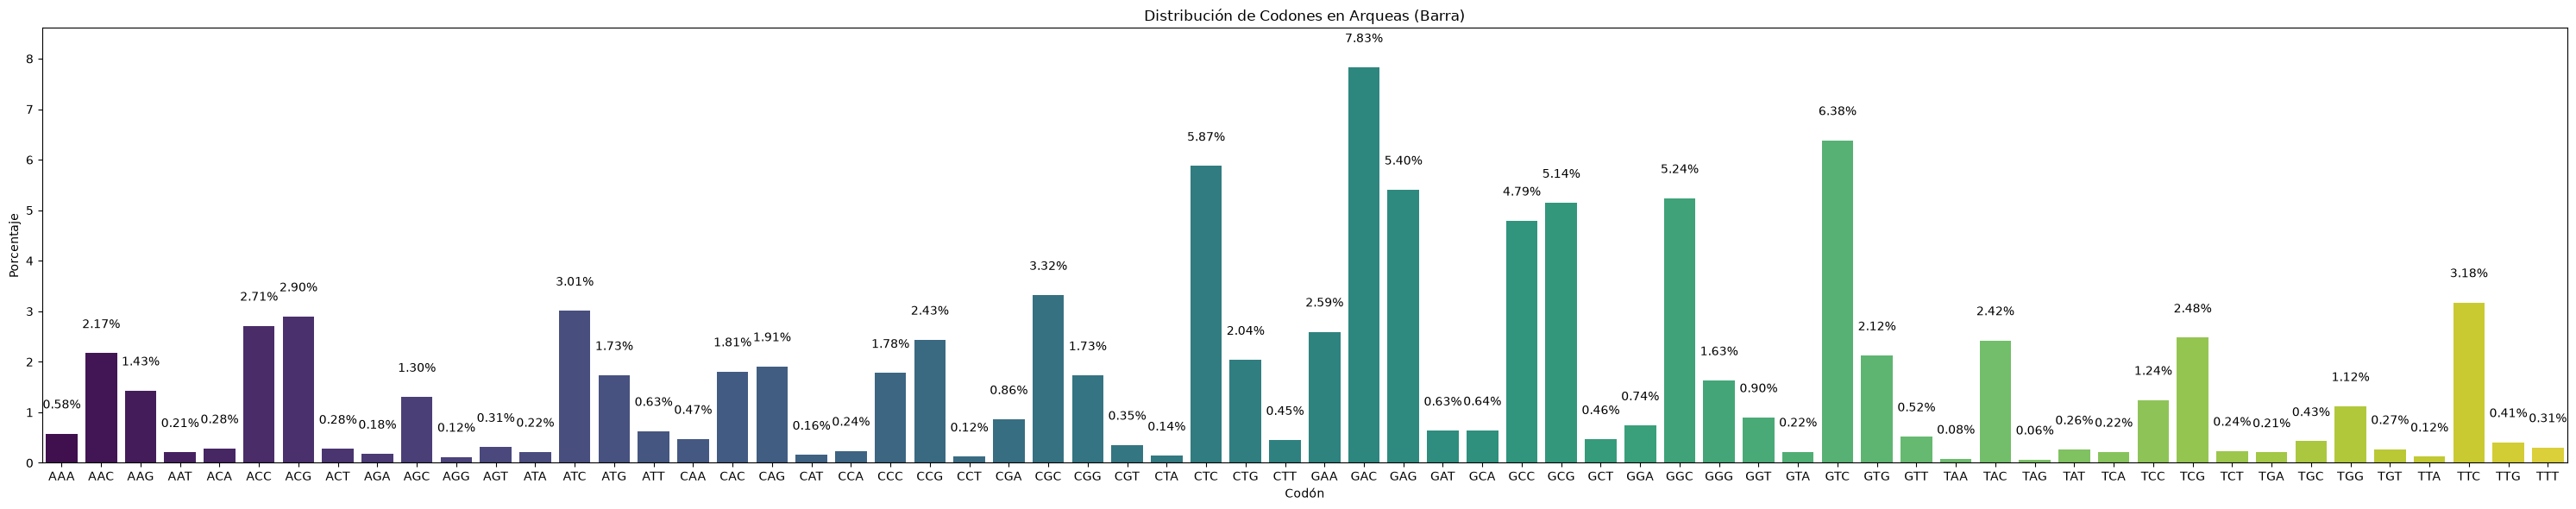

In [29]:
# Codon frequencies in archaea
plot_codon_freq_bar_chart(all_nucleotides_arqueas, title='Distribución de Codones en Arqueas (Barra)')

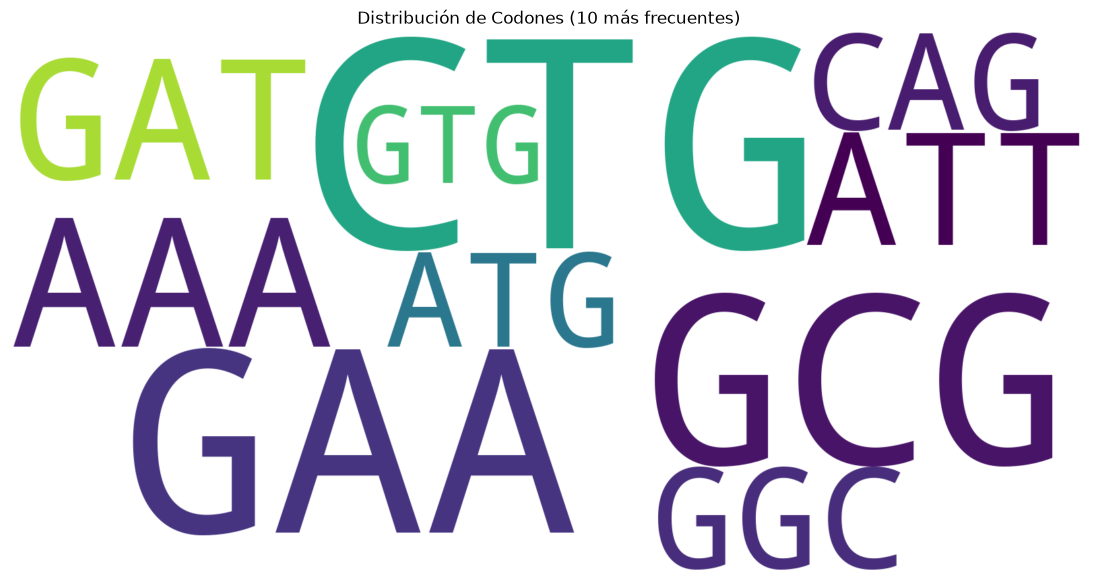

In [30]:
# Top 10 codons in E. coli
plot_codon_freq(all_nucleotides_ecoli)

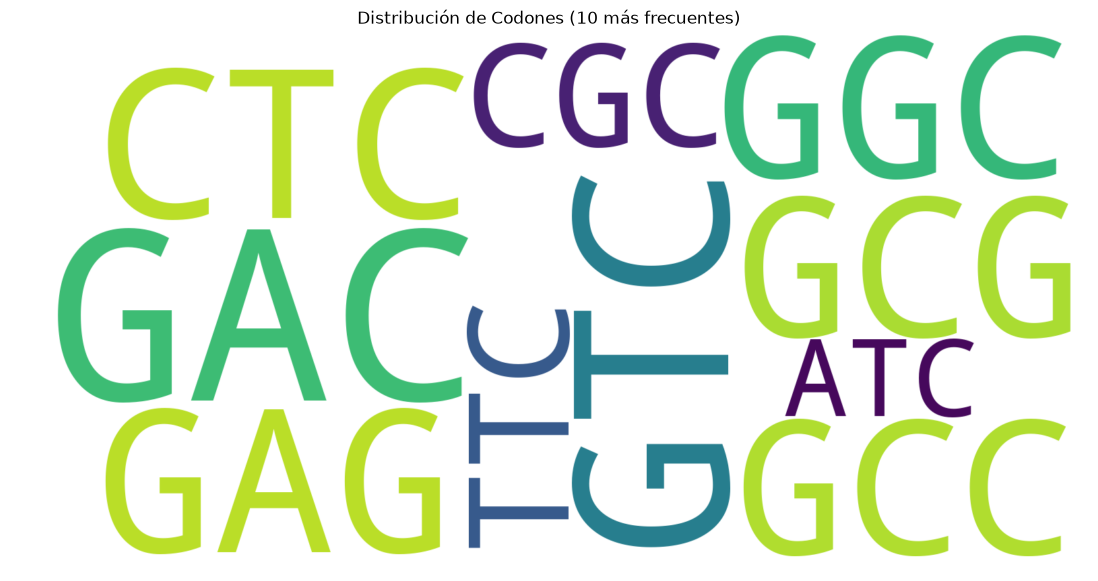

In [31]:
# Top 10 codons in archaea
plot_codon_freq(all_nucleotides_arqueas)

#### Codones de inicio y de parada

In [32]:
def plot_start_or_end_codon_freq(df, start, ax):
  """
  Plots the distribution of start or stop codons.

  Parameters
  ----------
  df : pandas.DataFrame
      Table with the column "secuencia".
  start : bool
      True for the first codon of each sequence, False for the last one.
  ax : matplotlib.axes.Axes
      Axes to draw on.
  """
  codon_counter = Counter(df["secuencia"].apply(lambda x: x[:3] if start else x[-3:]))
  plot_nucleotides(codon_counter, f'Distribución de Codones de {"Inicio" if start else "Fin"}', ax, x_label = "Codón")

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


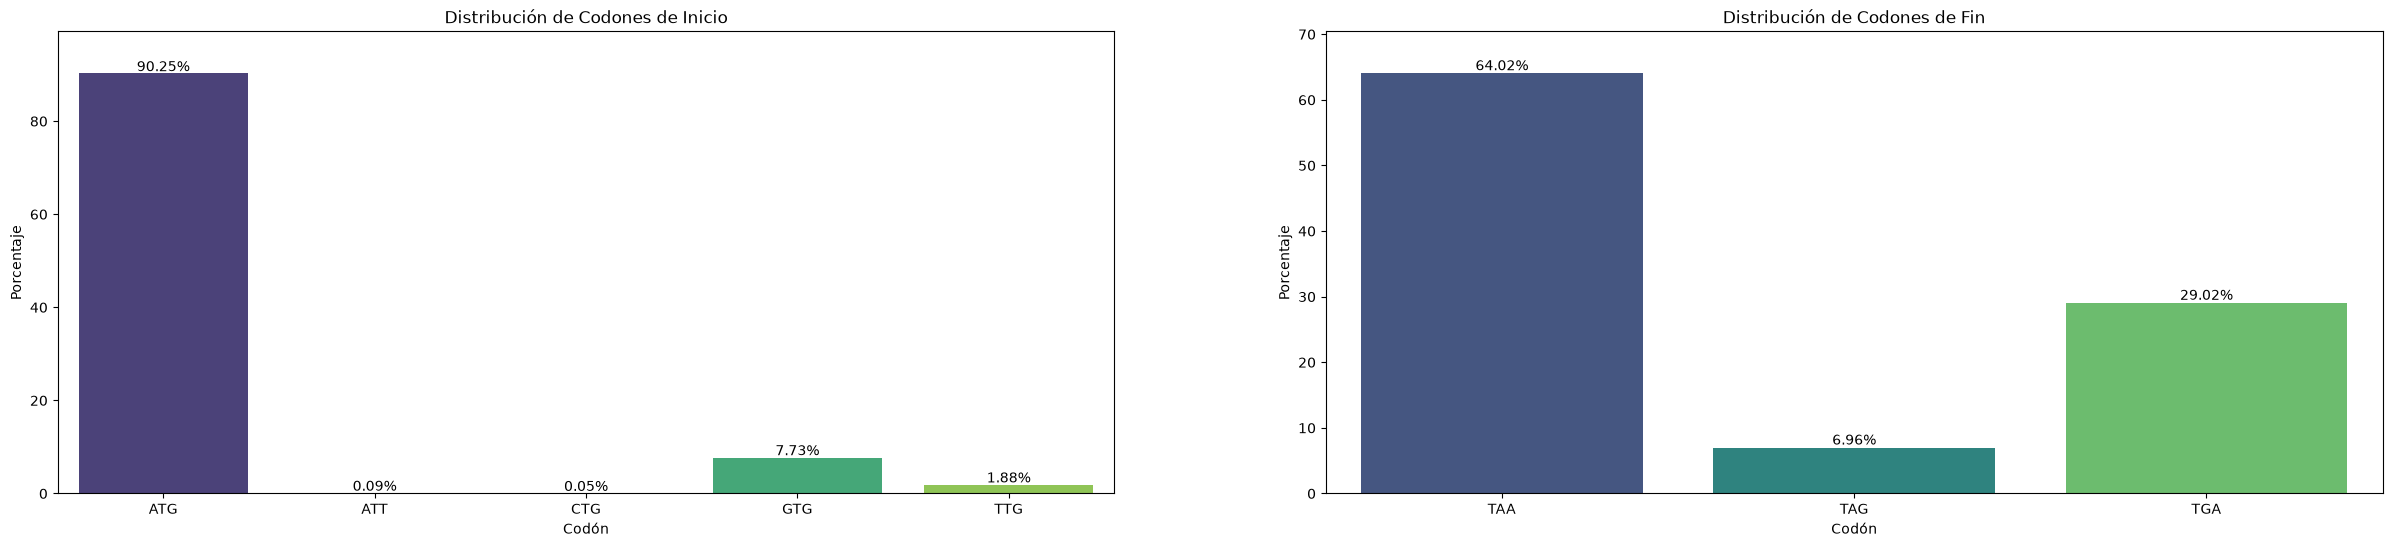

In [33]:
# Start and stop codons in E. coli
fig, axes = plt.subplots(1, 2, figsize=(30, 6))


plot_start_or_end_codon_freq(df_ecoli_limpio, True, axes[0])
plot_start_or_end_codon_freq(df_ecoli_limpio, False, axes[1])

/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)
/tmp/ipykernel_56741/1503904299.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=percentages.index, y=percentages.values, palette='viridis', ax=ax)


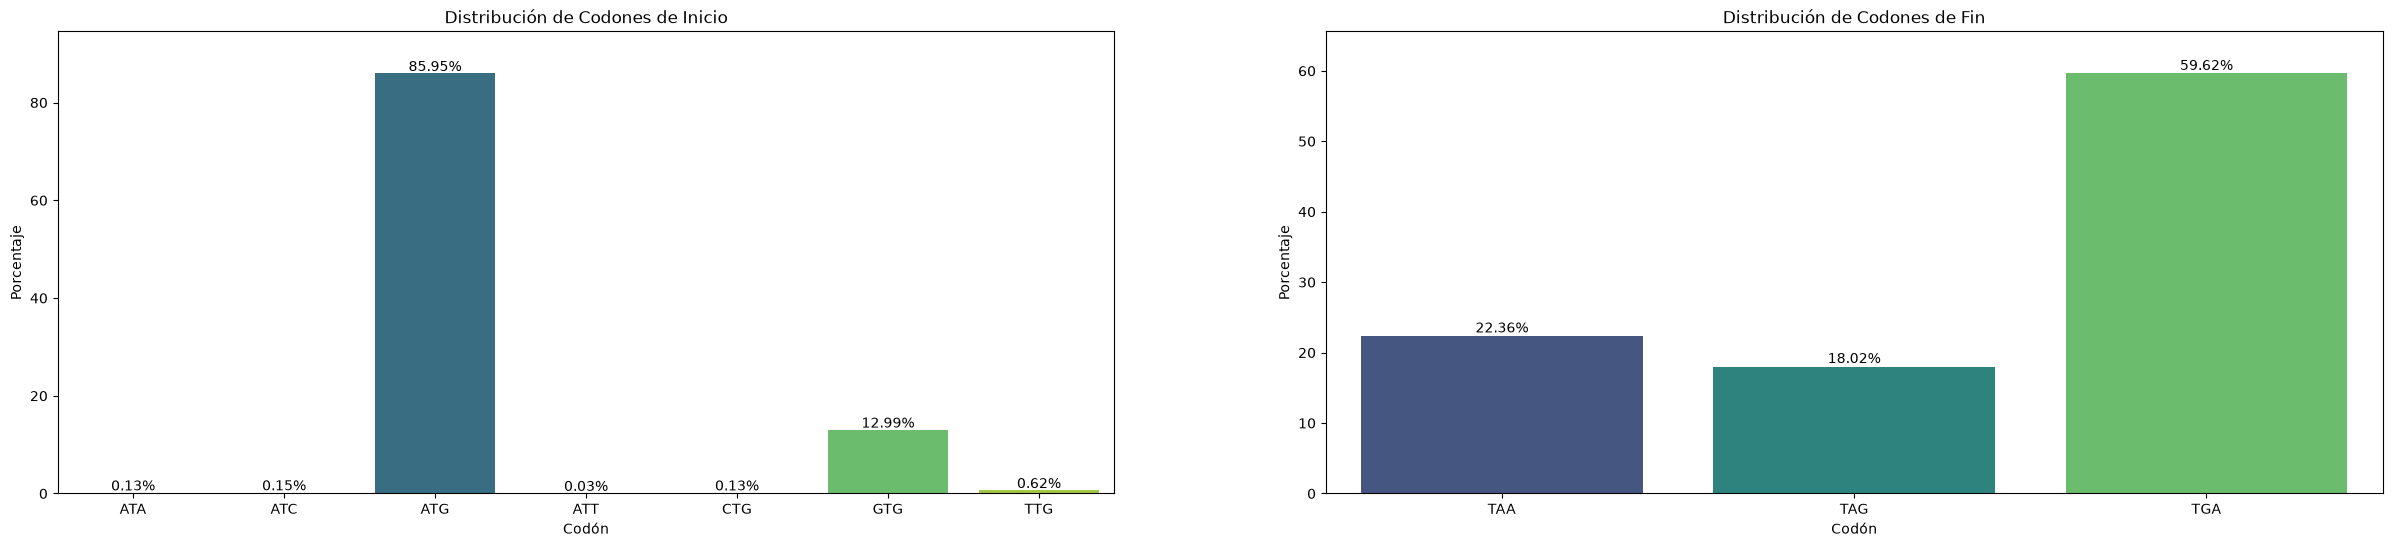

In [34]:
# Start and stop codons in archaea
fig, axes = plt.subplots(1, 2, figsize=(30, 6))


plot_start_or_end_codon_freq(df_arqueas_limpio, True, axes[0])
plot_start_or_end_codon_freq(df_arqueas_limpio, False, axes[1])

#### Longitud de las secuencias

In [35]:
def plot_length_histogram(df, title='Distribución de Longitud de Secuencias', x_label='Longitud de Secuencia'):
  """
  Prints the mean sequence length and plots a histogram of lengths with a KDE curve.

  Parameters
  ----------
  df : pandas.DataFrame
      Table with the column "longitud".
  title : str, optional
      Plot title.
  x_label : str, optional
      Label of the x axis.
  """
  print(df['longitud'].mean())
  plt.figure(figsize=(10, 6))
  sns.histplot(df['longitud'], kde=True, bins=30)
  plt.title(title)
  plt.xlabel(x_label)
  plt.ylabel('Frecuencia')
  plt.grid(axis='y', alpha=0.75)
  plt.show()

932.007285546416


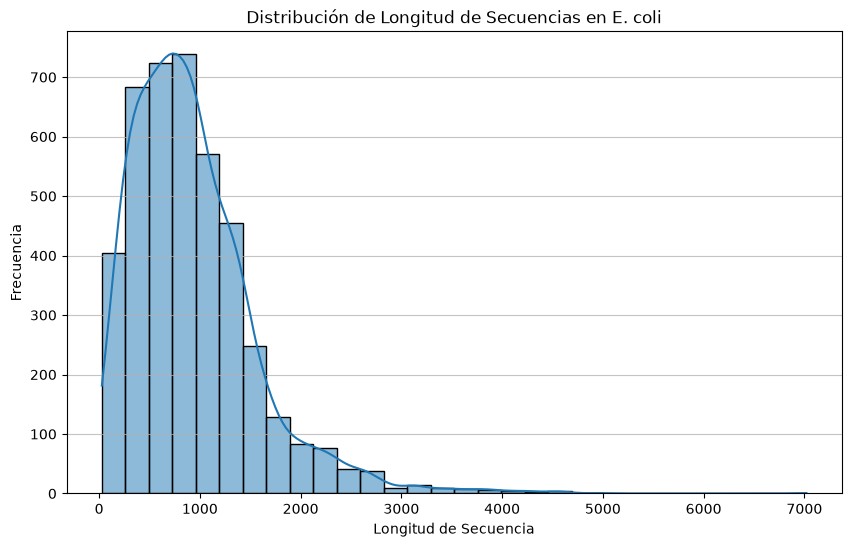

In [36]:
# Length distribution in E. coli
plot_length_histogram(df_ecoli_limpio, title='Distribución de Longitud de Secuencias en E. coli')

866.8605731990705


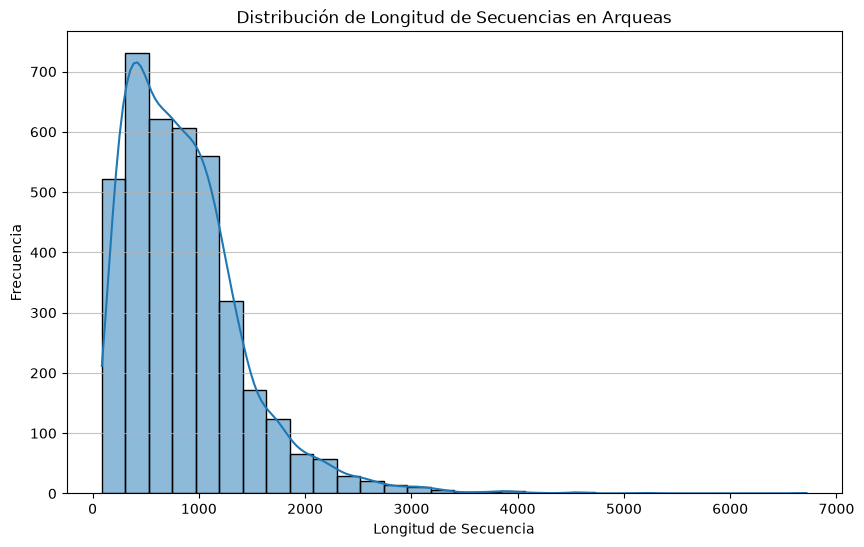

In [37]:
# Length distribution in archaea
plot_length_histogram(df_arqueas_limpio, title='Distribución de Longitud de Secuencias en Arqueas')

#### Contenido de GC

In [38]:
# Nucleotide counts per gene
df_ecoli_limpio["nucleotide_freq"] = df_ecoli_limpio["secuencia"].apply(lambda x: Counter(x))
df_arqueas_limpio["nucleotide_freq"] = df_arqueas_limpio["secuencia"].apply(lambda x: Counter(x))

In [39]:
def plot_nucleotide_dispersion(df, title):
    """
    Plots GC content (%) against sequence length, one point per gene.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the columns "longitud" and "gc".
    title : str
        Plot title.
    """
    df_for_plot = df[['longitud']].copy()
    df_for_plot['GC_Porcentaje'] = df['gc'] * 100

    plt.figure(figsize=(12, 8))
    sns.scatterplot(
        data=df_for_plot,
        x='longitud',
        y='GC_Porcentaje',
        alpha=0.6,
        s=10
    )
    plt.title(title)
    plt.xlabel('Longitud de Secuencia')
    plt.ylabel('Contenido de GC (%)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

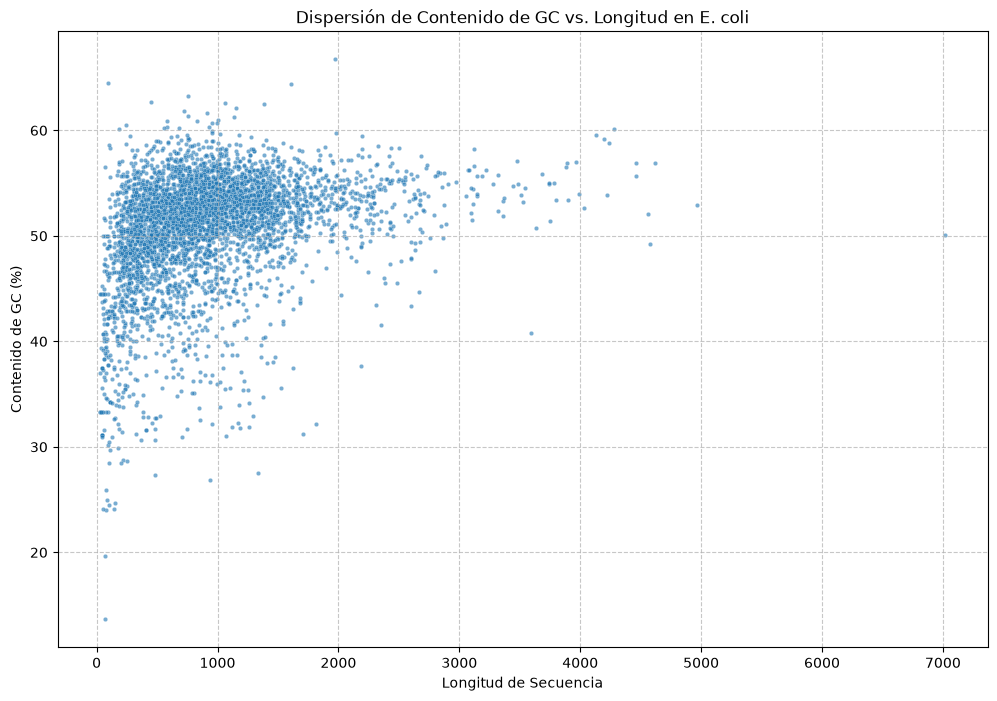

In [40]:
# GC content vs length in E. coli
plot_nucleotide_dispersion(df_ecoli_limpio, 'Dispersión de Contenido de GC vs. Longitud en E. coli')

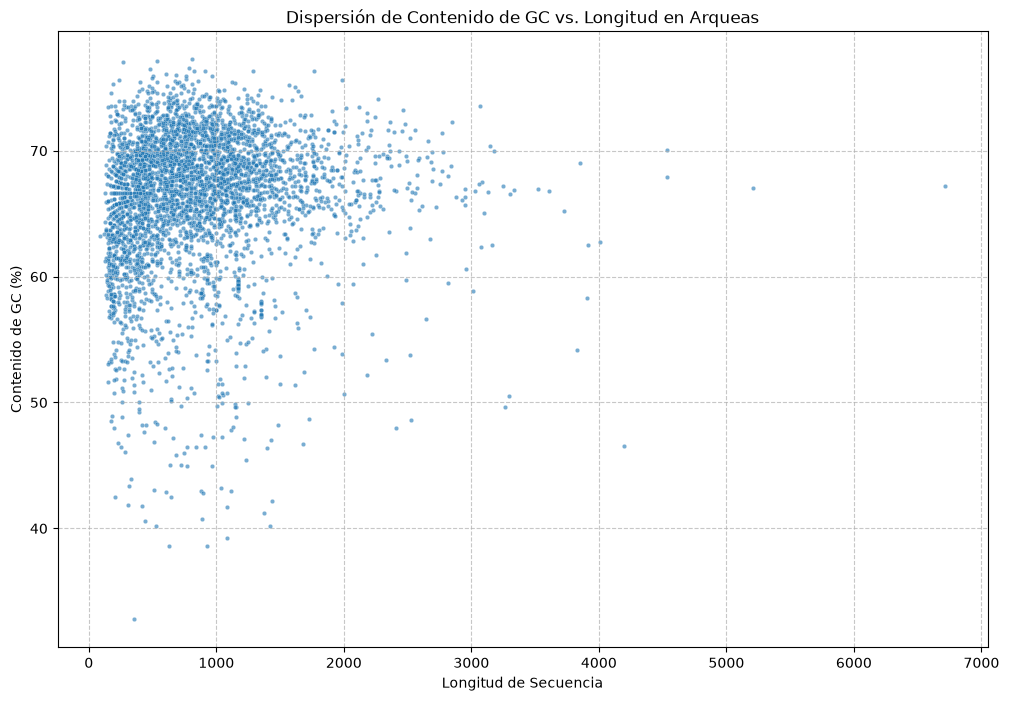

In [41]:
# GC content vs length in archaea
plot_nucleotide_dispersion(df_arqueas_limpio, 'Dispersión de Contenido de GC vs. Longitud en Arqueas')

In [42]:
# Inspect the clean archaea table
df_arqueas_limpio.head()

,id,replicon,gen,locus_tag,db_xref,proteina,protein_id,ubicacion,gbkey,pseudo,...,num_codones,gc,gc_pos1,gc_pos2,gc_pos3,codon_inicio,codon_parada,secuencia,duplicado,nucleotide_freq
0,lcl|NC_013967.1_cds_WP_004044954.1_1,NC_013967.1,NaN,HVO_RS04710,GeneID:8926884,Cdc6/Cdc18 family protein,WP_004044954.1,258..1952,CDS,NaN,...,565,0.648968,0.667257,0.378761,0.900885,ATG,TGA,ATGGACGAGGAAGAGAATCCGCGAGGCGGCGCACGAGGGGAAGCCG...,False,"{'A': 372, 'T': 223, 'G': 511, 'C': 589}"
1,lcl|NC_013967.1_cds_WP_004044955.1_2,NC_013967.1,NaN,HVO_RS04715,GeneID:8926122,S26 family signal peptidase,WP_004044955.1,complement(2000..2797),CDS,NaN,...,266,0.690476,0.684211,0.526316,0.860902,GTG,TGA,GTGCTAACTCGGCTTCGGACGGCAGAGGAGGGGCCGCTTCTGTTCG...,False,"{'G': 279, 'T': 109, 'C': 272, 'A': 138}"
2,lcl|NC_013967.1_cds_WP_004044956.1_3,NC_013967.1,NaN,HVO_RS04720,GeneID:8924320,DNA-directed DNA polymerase II small subunit,WP_004044956.1,2942..4543,CDS,NaN,...,534,0.667291,0.685393,0.425094,0.891386,GTG,TGA,GTGCCACTGGAGACGCCGGCGCGCATCGTCCGGACGCTCGTCGGTC...,False,"{'G': 472, 'T': 225, 'C': 597, 'A': 308}"
3,lcl|NC_013967.1_cds_WP_004044957.1_4,NC_013967.1,NaN,HVO_RS04725,GeneID:8924855,oxidoreductase,WP_004044957.1,4686..5813,CDS,NaN,...,376,0.708333,0.723404,0.473404,0.928191,ATG,TGA,ATGACCGACGACGCGCTGTTCGACGCGACGAGCCTGAACGACCTGT...,False,"{'A': 195, 'T': 134, 'G': 389, 'C': 410}"
4,lcl|NC_013967.1_cds_WP_013035623.1_5,NC_013967.1,NaN,HVO_RS04730,GeneID:8926047,ZIP family metal transporter,WP_013035623.1,complement(5936..6745),CDS,NaN,...,270,0.680247,0.670370,0.433333,0.937037,GTG,TAG,GTGACGGCGGTCGAAGAGCTGTTCGTCTCGCTCGCCGGCTCGAACC...,False,"{'G': 252, 'T': 150, 'A': 109, 'C': 299}"


In [43]:
# Inspect the clean E. coli table
df_ecoli_limpio.head()

,id,replicon,gen,locus_tag,db_xref,proteina,protein_id,ubicacion,gbkey,pseudo,...,num_codones,gc,gc_pos1,gc_pos2,gc_pos3,codon_inicio,codon_parada,secuencia,duplicado,nucleotide_freq
0,lcl|NC_000913.3_cds_NP_414542.1_1,NC_000913.3,thrL,b0001,UniProtKB/Swiss-Prot:P0AD86,thr operon leader peptide,NP_414542.1,190..255,CDS,NaN,...,22,0.515152,0.227273,0.681818,0.636364,ATG,TGA,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...,False,"{'A': 21, 'T': 11, 'G': 12, 'C': 22}"
1,lcl|NC_000913.3_cds_NP_414543.1_2,NC_000913.3,thrA,b0002,UniProtKB/Swiss-Prot:P00561,fused aspartate kinase/homoserine dehydrogenase 1,NP_414543.1,337..2799,CDS,NaN,...,821,0.530654,0.612667,0.403167,0.576127,ATG,TGA,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...,False,"{'A': 553, 'T': 603, 'G': 692, 'C': 615}"
2,lcl|NC_000913.3_cds_NP_414544.1_3,NC_000913.3,thrB,b0003,UniProtKB/Swiss-Prot:P00547,homoserine kinase,NP_414544.1,2801..3733,CDS,NaN,...,311,0.562701,0.627010,0.437299,0.623794,ATG,TAA,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...,False,"{'A': 195, 'T': 213, 'G': 294, 'C': 231}"
3,lcl|NC_000913.3_cds_NP_414545.1_4,NC_000913.3,thrC,b0004,UniProtKB/Swiss-Prot:P00934,threonine synthase,NP_414545.1,3734..5020,CDS,NaN,...,429,0.528361,0.613054,0.382284,0.589744,ATG,TAA,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...,False,"{'A': 305, 'T': 302, 'G': 364, 'C': 316}"
4,lcl|NC_000913.3_cds_NP_414546.1_5,NC_000913.3,yaaX,b0005,UniProtKB/Swiss-Prot:P75616,DUF2502 domain-containing protein YaaX,NP_414546.1,5234..5530,CDS,NaN,...,99,0.538721,0.696970,0.444444,0.474747,GTG,TAA,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...,False,"{'G': 77, 'T': 60, 'A': 77, 'C': 83}"


## 2. Partición de los datos (Entrega 2)

La partición se hace por grupos de genes parecidos (clusters de proteínas con MMseqs2) para que los parálogos queden en la misma partición.

In [44]:
# Keep only the id and the sequence of the clean E. coli genes
id_col, seq_col = "id", "secuencia"
df_ecoli_reduced = df_ecoli_limpio[[id_col, seq_col]].rename(columns={id_col: "id", seq_col: "seq"}).reset_index(drop=True)

In [45]:
# Translate the genes to proteins (table 11) for clustering
with open("ecoli_prot.faa", "w") as f:
    for i, s in zip(df_ecoli_reduced["id"], df_ecoli_reduced["seq"]):
        f.write(f">{i}\n{Seq(s).translate(table=11, to_stop=True)}\n")

In [46]:
# Cluster the proteins with MMseqs2 (50% identity, 80% coverage)
!mmseqs/bin/mmseqs easy-cluster ecoli_prot.faa clu tmp --min-seq-id 0.5 -c 0.8 --cov-mode 0 -v 1

In [47]:
# Assign each gene the cluster representative as its group (MMseqs2 drops the "lcl|" prefix, so it is restored)
clu = pd.read_csv("clu_cluster.tsv", sep="\t", header=None, names=["rep", "id"])
clu["rep"] = "lcl|" + clu["rep"]
clu["id"]  = "lcl|" + clu["id"]
df_ecoli_reduced = df_ecoli_reduced.merge(clu, on="id", how="left")
df_ecoli_reduced["group"] = df_ecoli_reduced["rep"].fillna(df_ecoli_reduced["id"])

print("Missing reps:", df_ecoli_reduced["rep"].isna().sum())

Missing reps: 0


In [48]:
# Inspect the genes with their group
df_ecoli_reduced.head()

,id,seq,rep,group
0,lcl|NC_000913.3_cds_NP_414542.1_1,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...,lcl|NC_000913.3_cds_NP_414542.1_1,lcl|NC_000913.3_cds_NP_414542.1_1
1,lcl|NC_000913.3_cds_NP_414543.1_2,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...,lcl|NC_000913.3_cds_NP_414543.1_2,lcl|NC_000913.3_cds_NP_414543.1_2
2,lcl|NC_000913.3_cds_NP_414544.1_3,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...,lcl|NC_000913.3_cds_NP_414544.1_3,lcl|NC_000913.3_cds_NP_414544.1_3
3,lcl|NC_000913.3_cds_NP_414545.1_4,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...,lcl|NC_000913.3_cds_NP_414545.1_4,lcl|NC_000913.3_cds_NP_414545.1_4
4,lcl|NC_000913.3_cds_NP_414546.1_5,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...,lcl|NC_000913.3_cds_NP_414546.1_5,lcl|NC_000913.3_cds_NP_414546.1_5


In [49]:
# Split by group: 80% train, then the remaining 20% in half for validation and test
SEED = 42

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, rest_idx = next(gss.split(df_ecoli_reduced, groups=df_ecoli_reduced["group"]))
train, rest = df_ecoli_reduced.iloc[train_idx], df_ecoli_reduced.iloc[rest_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
val_idx, test_idx = next(gss2.split(rest, groups=rest["group"]))
val, test = rest.iloc[val_idx], rest.iloc[test_idx]

In [50]:
# Label each gene with its split and save the assignment
df_ecoli_reduced["split"] = "train"
df_ecoli_reduced.loc[df_ecoli_reduced["id"].isin(val["id"]),  "split"] = "val"
df_ecoli_reduced.loc[df_ecoli_reduced["id"].isin(test["id"]), "split"] = "test"
df_ecoli_reduced[["id", "group", "split"]].to_csv("ecoli_splits.csv", index=False)

In [51]:
# Sanity checks: split proportions and no group shared between splits
print(df_ecoli_reduced["split"].value_counts(normalize=True))
print("Clusters:", df_ecoli_reduced["group"].nunique(), "| multi-gene clusters:",
      (df_ecoli_reduced["group"].value_counts() > 1).sum())
assert not set(train["group"]) & set(val["group"])
assert not set(train["group"]) & set(test["group"])
assert not set(val["group"]) & set(test["group"])

split
train    0.800705
test     0.101763
val      0.097532
Name: proportion, dtype: float64
Clusters: 4055 | multi-gene clusters: 164


In [52]:
# Inspect the genes with their split
df_ecoli_reduced.head()

,id,seq,rep,group,split
0,lcl|NC_000913.3_cds_NP_414542.1_1,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...,lcl|NC_000913.3_cds_NP_414542.1_1,lcl|NC_000913.3_cds_NP_414542.1_1,train
1,lcl|NC_000913.3_cds_NP_414543.1_2,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...,lcl|NC_000913.3_cds_NP_414543.1_2,lcl|NC_000913.3_cds_NP_414543.1_2,train
2,lcl|NC_000913.3_cds_NP_414544.1_3,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...,lcl|NC_000913.3_cds_NP_414544.1_3,lcl|NC_000913.3_cds_NP_414544.1_3,train
3,lcl|NC_000913.3_cds_NP_414545.1_4,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...,lcl|NC_000913.3_cds_NP_414545.1_4,lcl|NC_000913.3_cds_NP_414545.1_4,train
4,lcl|NC_000913.3_cds_NP_414546.1_5,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...,lcl|NC_000913.3_cds_NP_414546.1_5,lcl|NC_000913.3_cds_NP_414546.1_5,train


In [53]:
# Training genes
train_df = df_ecoli_reduced.loc[df_ecoli_reduced["split"] == 'train'].copy()
len(train_df)

3407

In [54]:
# Validation genes
val_df = df_ecoli_reduced.loc[df_ecoli_reduced["split"] == 'val'].copy()
len(val_df)

415

In [55]:
# Test genes
test_df = df_ecoli_reduced.loc[df_ecoli_reduced["split"] == 'test'].copy()
len(test_df)

433

## 3. Simulación de errores

Se inyectan sustituciones con dos perfiles: uniforme y realista (más errores hacia el final de cada lectura simulada y después de homopolímeros, según Stoler y Nekrutenko). Los errores de validación y prueba se generan una sola vez con semillas fijas; los de entrenamiento se generan de nuevo en cada época.

In [56]:
def create_errors(seq, rate, rng, profile="realistic", read_len=150, slope=3.0,
                  homo_boost=3.0, min_run=3, p_repeat=0.5):
    """
    Injects random substitutions into a sequence and returns the noisy sequence.

    With the "uniform" profile every position has the same error probability. With the
    "realistic" profile the probability grows linearly along each simulated read of
    read_len nucleotides and is multiplied by homo_boost right after a homopolymer of at
    least min_run bases; probabilities are then rescaled so their mean equals rate. At a
    post-homopolymer position the substitution repeats the previous base with probability
    p_repeat; otherwise the new base is drawn uniformly among the three other bases, so
    every marked position is a real substitution.

    Parameters
    ----------
    seq : str
        Clean nucleotide sequence.
    rate : float
        Mean substitution probability per position.
    rng : numpy.random.Generator
        Random generator.
    profile : {"realistic", "uniform"}, optional
        Error profile.
    read_len : int, optional
        Length of the simulated reads for the positional gradient.
    slope : float, optional
        Relative increase of the error weight from the start to the end of a read.
    homo_boost : float, optional
        Factor applied to the error weight right after a homopolymer.
    min_run : int, optional
        Minimum run length that counts as a homopolymer.
    p_repeat : float, optional
        Probability that a post-homopolymer error repeats the previous base.

    Returns
    -------
    noisy : str
        Sequence with substitutions, same length as seq.
    is_error : numpy.ndarray of bool
        True at the substituted positions.
    """
    n = len(seq)
    post_homo = np.zeros(n, dtype=bool)

    if profile == "uniform":
        probs = np.full(n, rate)
    else:
        pos_in_read = np.arange(n) % read_len
        w = 1 + slope * pos_in_read / (read_len - 1)
        run = 1
        for i in range(1, n):
            if seq[i] != seq[i-1] and run >= min_run:
                w[i] *= homo_boost
                post_homo[i] = True
            run = run + 1 if seq[i] == seq[i-1] else 1
        probs = w * (rate / w.mean())

    is_error = rng.random(n) < probs

    chars = list(seq)
    for i in np.flatnonzero(is_error):
        if post_homo[i] and rng.random() < p_repeat:
            chars[i] = seq[i-1]
        else:
            chars[i] = rng.choice([b for b in "ACGT" if b != seq[i]])

    return "".join(chars), is_error

In [57]:
# Error rates, error profiles and number of test seeds of the experiments
RATES = {"0.1pct": 0.001, "1pct": 0.01, "5pct": 0.05}
PROFILES = ["uniform", "realistic"]
N_TEST_SEEDS = 5

In [58]:
def noisy_col_name(r_name, profile, seed):
    """
    Builds the name of the column that stores a precomputed noisy version of the genes.

    Parameters
    ----------
    r_name : str
        Error rate name, a key of RATES.
    profile : str
        Error profile, an element of PROFILES.
    seed : int
        Seed index.

    Returns
    -------
    name : str
        Column name, e.g. "noisy_1pct_uniform_s0".
    """
    return f"noisy_{r_name}_{profile}_s{seed}"

In [59]:
def add_noisy_columns(df, n_seeds, set_id):
    """
    Adds one column of noisy sequences per error rate, profile and seed.

    Each column uses its own generator seeded with (set_id, rate, profile, seed), so the
    errors are reproducible and independent between sets and configurations.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the column "seq". It is modified in place.
    n_seeds : int
        Number of noisy versions per rate and profile.
    set_id : int
        Identifier of the set (e.g. 1 for validation, 2 for test) used in the seed.

    Returns
    -------
    df : pandas.DataFrame
        The same table with the new columns.
    """
    for r_name, rate in RATES.items():
        for p_id, profile in enumerate(PROFILES):
            for seed in range(n_seeds):
                rng = np.random.default_rng([set_id, int(rate * 10000), p_id, seed])
                df[noisy_col_name(r_name, profile, seed)] = [
                    create_errors(s, rate, rng, profile=profile)[0] for s in df["seq"]
                ]
    return df

In [60]:
# Generate the fixed validation (1 seed) and test (5 seeds) errors once and save them
val_df  = add_noisy_columns(val_df,  n_seeds=1,            set_id=1)
test_df = add_noisy_columns(test_df, n_seeds=N_TEST_SEEDS, set_id=2)
val_df.to_csv("val_noisy.csv", index=False)
test_df.to_csv("test_noisy.csv", index=False)

In [ ]:
# Keep only the id and the sequence of the clean archaea genes, the out-of-domain test set (never used for training or model selection)
arch_df = df_arqueas_limpio[["id", "secuencia"]].rename(columns={"secuencia": "seq"}).reset_index(drop=True)

In [ ]:
# Generate the fixed archaea errors once, with the same rates, profiles and number of seeds as the test set, and save them
arch_df = add_noisy_columns(arch_df, n_seeds=N_TEST_SEEDS, set_id=3)
arch_df.to_csv("arch_noisy.csv", index=False)

## 4. Datasets y DataLoaders

In [61]:
# GENERanno tokenizer (one token per nucleotide); requires transformers 4.x (tested with 4.44.0 and 4.57.3)
MODEL_NAME = "GenerTeam/GENERanno-prokaryote-0.5b-base"
MODEL_REVISION = "d02db0f24f2c62fa1efde760217cdf75771b0228"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, trust_remote_code=True)

In [62]:
# Nucleotide alphabet; its order defines the class index of each base
BASES = "ACGT"
BASE2ID = {b: i for i, b in enumerate(BASES)}

In [63]:
class SeqDataset(Dataset):
    """
    Dataset of genes with substitutions for training and evaluating the corrector.

    In training mode the errors are created on the fly, so every epoch sees new errors.
    In evaluation mode the noisy sequences are read from a precomputed column. Each item
    is the tokenized noisy sequence with "<s>" at the start, its labels (the clean base
    at each position) and the error mask.
    """

    def __init__(self, df, tokenizer, error_func=None, error_kwargs=None, noisy_col=None):
        """
        Parameters
        ----------
        df : pandas.DataFrame
            Table with the column "seq" (and noisy_col in evaluation mode).
        tokenizer : transformers.PreTrainedTokenizer
            GENERanno tokenizer.
        error_func : callable, optional
            Error generator with the signature of create_errors; required for training.
        error_kwargs : dict, optional
            Keyword arguments for error_func; must include "rate".
        noisy_col : str, optional
            Column with precomputed noisy sequences; if given, the dataset is in
            evaluation mode.

        Raises
        ------
        ValueError
            If noisy_col is None and error_func or error_kwargs["rate"] is missing.
        """

        if noisy_col is None:
              if error_func is None:
                  raise ValueError("Training mode needs error_func (or pass noisy_col for val/test).")
              if "rate" not in (error_kwargs or {}):
                  raise ValueError("error_kwargs must include 'rate'.")

        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.error_func = error_func
        self.error_kwargs = error_kwargs or {}
        self.noisy_col = noisy_col
        self.rng = None

    def _get_rng(self):
        """
        Returns the random generator, creating it on first use.

        It is created lazily inside each DataLoader worker and seeded from
        torch.initial_seed(), so different workers produce different errors.

        Returns
        -------
        rng : numpy.random.Generator
            Generator used to create the training errors.
        """
        if self.rng is None:
            self.rng = np.random.default_rng(torch.initial_seed() % 2**32)
        return self.rng

    def __len__(self):
        """
        Returns
        -------
        n : int
            Number of genes.
        """
        return len(self.df)

    def __getitem__(self, idx):
        """
        Builds the example for one gene.

        Parameters
        ----------
        idx : int
            Gene index.

        Returns
        -------
        item : dict of str to torch.Tensor
            "input_ids": "<s>" followed by one token per noisy nucleotide.
            "attention_mask": ones, same length as input_ids.
            "labels": -100 for "<s>" (ignored by the loss), then the clean base index.
            "is_error": False for "<s>", then True at the substituted positions.
        """
        seq = self.df.loc[idx, "seq"]

        if self.noisy_col is not None:
            noisy = self.df.loc[idx, self.noisy_col]
            is_error = np.array([a != b for a, b in zip(seq, noisy)])
        else:
            noisy, is_error = self.error_func(seq, rng=self._get_rng(), **self.error_kwargs)

        enc = self.tokenizer("<s>" + noisy, add_special_tokens=False)
        input_ids = torch.tensor(enc["input_ids"])
        assert len(input_ids) == len(seq) + 1, "expected <s> + 1 token per nucleotide"

        labels = torch.tensor([-100] + [BASE2ID[b] for b in seq])
        is_error = torch.tensor(np.concatenate([[False], is_error]))

        return {
            "input_ids": input_ids,
            "attention_mask": torch.ones_like(input_ids),
            "labels": labels,
            "is_error": is_error,
        }

In [64]:
def collate(batch, pad_id):
    """
    Pads a list of examples up to the longest sequence of the batch.

    Parameters
    ----------
    batch : list of dict
        Items as returned by SeqDataset.__getitem__.
    pad_id : int
        Token id used to pad input_ids.

    Returns
    -------
    batch : dict of str to torch.Tensor
        Tensors of shape [batch, length]; padding has attention_mask 0, label -100 and
        is_error False.
    """
    return {
        "input_ids":      pad_sequence([b["input_ids"] for b in batch], batch_first=True, padding_value=pad_id),
        "attention_mask": pad_sequence([b["attention_mask"] for b in batch], batch_first=True, padding_value=0),
        "labels":         pad_sequence([b["labels"] for b in batch], batch_first=True, padding_value=-100),
        "is_error":       pad_sequence([b["is_error"] for b in batch], batch_first=True, padding_value=False),
    }

In [65]:
# Build the datasets: training with on-the-fly errors, validation and test with the fixed errors
training_sets, validation_sets, test_sets = {}, {}, {}

for r_name, rate in RATES.items():
    for profile in PROFILES:
        training_sets[(r_name, profile)] = SeqDataset(
            train_df, tokenizer,
            error_func=create_errors,
            error_kwargs={"rate": rate, "profile": profile},
        )
        validation_sets[(r_name, profile)] = SeqDataset(
            val_df, tokenizer, noisy_col=noisy_col_name(r_name, profile, 0)
        )
        for seed in range(N_TEST_SEEDS):
            test_sets[(r_name, profile, seed)] = SeqDataset(
                test_df, tokenizer, noisy_col=noisy_col_name(r_name, profile, seed)
            )

In [66]:
def make_dataloader(dataset, batch_size, shuffle=False, seed=42):
    """
    Creates a DataLoader that pads each batch with the "<s>" token.

    Parameters
    ----------
    dataset : SeqDataset
        Dataset to iterate.
    batch_size : int
        Number of genes per batch.
    shuffle : bool, optional
        Whether to shuffle the genes every epoch.
    seed : int, optional
        Seed of the shuffling generator, so the order is reproducible.

    Returns
    -------
    loader : torch.utils.data.DataLoader
        DataLoader whose batches are dicts as returned by collate.
    """
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=partial(collate, pad_id=tokenizer.convert_tokens_to_ids("<s>")),
        generator=generator if shuffle else None,
    )

In [67]:
def make_dataloaders(training_sets, validation_sets, test_sets, batch_size, seed=42):
    """
    Creates the DataLoaders of every configuration.

    Training loaders shuffle the genes; validation and test loaders keep their order,
    which the metrics rely on to match predictions with the original sequences.

    Parameters
    ----------
    training_sets : dict
        Training datasets keyed by (r_name, profile).
    validation_sets : dict
        Validation datasets keyed by (r_name, profile).
    test_sets : dict
        Test datasets keyed by (r_name, profile, seed).
    batch_size : int
        Number of genes per batch.
    seed : int, optional
        Seed of the training shuffling.

    Returns
    -------
    training_loaders : dict
        Training DataLoaders keyed by (r_name, profile).
    validation_loaders : dict
        Validation DataLoaders keyed by (r_name, profile).
    test_loaders : dict
        Test DataLoaders keyed by (r_name, profile, seed).
    """

    training_loaders = {
        (r_name, profile): make_dataloader(ds, batch_size, shuffle=True, seed=seed)
        for (r_name, profile), ds in training_sets.items()
    }

    validation_loaders = {
        (r_name, profile): make_dataloader(ds, batch_size, shuffle=False)
        for (r_name, profile), ds in validation_sets.items()
    }

    test_loaders = {
        (r_name, profile, seed): make_dataloader(ds, batch_size, shuffle=False)
        for (r_name, profile, seed), ds in test_sets.items()
    }

    return training_loaders, validation_loaders, test_loaders

## 5. Líneas base

In [68]:
# Padding symbol of the n-gram model
PAD = "<s>"

In [69]:
class NGramLinearInterpolationModel:
    """
    Bidirectional n-gram corrector with linear interpolation.

    A forward model is trained on the sequences and a reverse model on the reversed
    sequences. Each candidate base at a position is scored with the sum of the log
    probabilities given by its left context (forward model) and its right context
    (reverse model), plus a noisy-channel prior that favors the observed base: log(1 - e)
    if the candidate is the observed base and log(e / 3) otherwise, e being the assumed
    error rate. Without the prior the model would change every base its context does not
    prefer, even by a tiny margin. The scores are normalized with a softmax over A, C, G, T.
    """

    def __init__(self, n, lambdas, error_rate=0.01):
        """
        Parameters
        ----------
        n : int
            Maximum n-gram order.
        lambdas : sequence of float
            Interpolation weights, lambdas[i-1] being the weight of order i; they must
            sum to 1.
        error_rate : float, optional
            Assumed substitution rate e of the noisy-channel prior, in (0, 1). Lower values
            make the model more conservative (it changes fewer bases).
        """
        assert len(lambdas) == n and abs(sum(lambdas) - 1) < 1e-9
        assert 0 < error_rate < 1
        self.n = n
        self.lambdas = lambdas
        self.error_rate = error_rate
        self.ngram_counters = {i: Counter() for i in range(1, n + 1)}
        self.reverse_ngram_counters = {i: Counter() for i in range(1, n + 1)}

    def fit(self, sequences):
        """
        Counts the n-grams of the forward and reverse sequences.

        Parameters
        ----------
        sequences : iterable of str
            Clean training sequences.

        Returns
        -------
        self : NGramLinearInterpolationModel
            The fitted model.
        """
        sequences = list(sequences)
        padded = self._pad_sequences(sequences)
        padded_reverse = self._pad_sequences([seq[::-1] for seq in sequences])
        self._count(padded, self.ngram_counters)
        self._count(padded_reverse, self.reverse_ngram_counters)
        return self

    def _count(self, sequence_list, counters):
        """
        Adds to counters every n-gram of order 1..n ending at a real base, and its context.

        Parameters
        ----------
        sequence_list : list of list of str
            Padded sequences.
        counters : dict of int to collections.Counter
            Counters per order, updated in place.
        """
        for seq in sequence_list:
            for j in range(self.n - 1, len(seq)):
                for i in range(1, self.n + 1):
                    ngram = tuple(seq[j - i + 1 : j + 1])
                    counters[i][ngram] += 1
                    counters[i][ngram[:-1]] += 1

    def get_prob(self, ngram, reverse=False, log=False):
        """
        Computes the interpolated probability of the last symbol of an n-gram given its context.

        Orders whose context was never seen contribute 0.

        Parameters
        ----------
        ngram : sequence of str
            n-1 context symbols (nearest last) followed by the candidate base.
        reverse : bool, optional
            Use the reverse (right-context) model.
        log : bool, optional
            Return the natural log of the probability.

        Returns
        -------
        prob : float
            Interpolated probability, or its log.
        """
        counters = self.reverse_ngram_counters if reverse else self.ngram_counters
        ngram = tuple(ngram)
        prob = 0.0
        for i in range(1, self.n + 1):
            working_ngram = ngram[-i:]
            count_context = counters[i][working_ngram[:-1]]
            if count_context > 0:
                prob += self.lambdas[i - 1] * counters[i][working_ngram] / count_context
        return math.log(prob) if log else prob

    def predict_one(self, seq):
        """
        Corrects one sequence by choosing the most probable base at each position, given
        its context and the observed base.

        Parameters
        ----------
        seq : str
            Noisy sequence.

        Returns
        -------
        corrected : str
            Sequence with the most probable base at each position.
        probs : numpy.ndarray
            Array of shape [len(seq), 4] with the probability of A, C, G, T at each position.
        """
        pad = [PAD] * (self.n - 1)
        toks = pad + list(seq) + pad
        log_scores = np.zeros((len(seq), 4))
        log_keep, log_change = math.log(1 - self.error_rate), math.log(self.error_rate / 3)
        for j in range(len(seq)):
            k = j + self.n - 1
            left_ctx = toks[k - (self.n - 1) : k]
            right_ctx = toks[k + 1 : k + self.n][::-1]
            for b in BASES:
                log_scores[j, BASE2ID[b]] = (
                    self.get_prob(left_ctx + [b], log=True)
                    + self.get_prob(right_ctx + [b], reverse=True, log=True)
                    + (log_keep if b == seq[j] else log_change)
                )
        log_scores -= log_scores.max(axis=1, keepdims=True)
        probs = np.exp(log_scores)
        softmax = probs / probs.sum(axis=1, keepdims=True)
        best_idx = softmax.argmax(axis=1)
        corrected = "".join(BASES[i] for i in best_idx)
        return corrected, softmax

    def predict(self, sequences):
        """
        Corrects several sequences.

        Parameters
        ----------
        sequences : iterable of str
            Noisy sequences.

        Returns
        -------
        preds : list of tuple of (str, numpy.ndarray)
            (corrected, probs) per sequence, as returned by predict_one.
        """
        return [self.predict_one(seq) for seq in sequences]

    def _pad_sequences(self, sequences):
        """
        Prepends n-1 padding symbols to each sequence.

        Parameters
        ----------
        sequences : list of str
            Sequences to pad.

        Returns
        -------
        padded : list of list of str
            Padded sequences as lists of symbols.
        """
        return [[PAD] * (self.n - 1) + list(seq) for seq in sequences]

In [70]:
class FrequencyCorrector:
    """
    Random corrector that knows where the errors are.

    At each known error position it draws a replacement among the other three bases,
    with probabilities proportional to their frequency in the training sequences. It
    gives a reference for the correction step when detection is perfect.
    """

    def __init__(self, seed=0):
        """
        Parameters
        ----------
        seed : int, optional
            Seed of the random generator.
        """
        self.base_counter = Counter()
        self.probs_remove_one = {}
        self.rng = np.random.default_rng(seed)

    def fit(self, sequences):
        """
        Computes, for each base, the frequencies of the other three bases.

        Parameters
        ----------
        sequences : iterable of str
            Clean training sequences.

        Returns
        -------
        self : FrequencyCorrector
            The fitted corrector.
        """
        self.base_counter = Counter("".join(sequences))
        for removed in BASES:
            temp_counter = self.base_counter.copy()
            temp_counter[removed] = 0
            total_count = sum(temp_counter.values())
            self.probs_remove_one[removed] = [temp_counter[b] / total_count for b in BASES]
        return self

    def _predict_one(self, seq, is_error):
        """
        Replaces the bases at the error positions of one sequence.

        Parameters
        ----------
        seq : str
            Noisy sequence.
        is_error : array-like of bool
            True at the error positions.

        Returns
        -------
        corrected : str
            Sequence with a random replacement at each error position.
        """
        fixed = []
        for i, nucleotide in enumerate(seq):
            new_nucleotide = nucleotide
            if is_error[i]:
                new_nucleotide = self.rng.choice(list(BASES), p=self.probs_remove_one[nucleotide])
            fixed.append(new_nucleotide)
        return "".join(fixed)

    def predict(self, sequences, is_error):
        """
        Corrects several sequences.

        Parameters
        ----------
        sequences : iterable of str
            Noisy sequences.
        is_error : iterable of array-like of bool
            Error masks, one per sequence.

        Returns
        -------
        corrected : list of str
            Corrected sequences.
        """
        return [self._predict_one(seq, error_array) for seq, error_array in zip(sequences, is_error)]

In [71]:
class NoChangeCorrector:
    """
    Trivial corrector that returns its input unchanged (gain 0).
    """

    def fit(self, sequences):
        """
        Does nothing; there is nothing to learn.

        Parameters
        ----------
        sequences : iterable of str
            Ignored.

        Returns
        -------
        self : NoChangeCorrector
            The corrector.
        """
        return self

    def predict(self, sequences):
        """
        Returns the sequences unchanged.

        Parameters
        ----------
        sequences : iterable of str
            Noisy sequences.

        Returns
        -------
        corrected : list of str
            The same sequences.
        """
        return list(sequences)

In [72]:
# Weights dtype: bfloat16 only on GPUs with native support (A100, L4); float32 elsewhere (e.g. T4), where bfloat16 falls back to slow attention with quadratic memory
DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported(including_emulation=False) else torch.float32

In [73]:
# Zero-shot model: GENERanno with its masked language modeling head
backbone = AutoModelForMaskedLM.from_pretrained(
    MODEL_NAME, revision=MODEL_REVISION, trust_remote_code=True, torch_dtype=DTYPE
)

`torch_dtype` is deprecated! Use `dtype` instead!


## 6. Modelo GENERanno

In [74]:
# Separate copy of the encoder for fine-tuning, with non-reentrant gradient checkpointing so the ~7k nt genes fit in memory and LoRA gets gradients
encoder = AutoModelForMaskedLM.from_pretrained(
    MODEL_NAME, revision=MODEL_REVISION, trust_remote_code=True, torch_dtype=DTYPE
).model
encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

In [75]:
# Print the model structure to inspect its layers
print(backbone)

GenerannoForMaskedLM(
  (model): GenerannoModel(
    (embed_tokens): Embedding(64, 1280, padding_idx=3)
    (layers): ModuleList(
      (0-27): 28 x GenerannoEncoderLayer(
        (self_attn): GenerannoSdpaAttention(
          (q_proj): Linear(in_features=1280, out_features=1280, bias=False)
          (k_proj): Linear(in_features=1280, out_features=320, bias=False)
          (v_proj): Linear(in_features=1280, out_features=320, bias=False)
          (o_proj): Linear(in_features=1280, out_features=1280, bias=False)
          (rotary_emb): GenerannoRotaryEmbedding()
        )
        (mlp): GenerannoMLP(
          (gate_proj): Linear(in_features=1280, out_features=3520, bias=False)
          (up_proj): Linear(in_features=1280, out_features=3520, bias=False)
          (down_proj): Linear(in_features=3520, out_features=1280, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): GenerannoRMSNorm((1280,), eps=1e-05)
        (post_attention_layernorm): Generanno

In [76]:
class ClassificationHead(nn.Module):
    """
    Per-token classification head: an MLP from the hidden states to the class logits.

    Each hidden layer is Linear, activation and Dropout; a final Linear layer outputs
    num_classes logits.
    """

    def __init__(self, hidden_size, layer_sizes=(256, 128), dropout=0.1, num_classes=4, activation=nn.GELU):
        """
        Parameters
        ----------
        hidden_size : int
            Size of the input hidden states.
        layer_sizes : tuple of int, optional
            Sizes of the hidden layers.
        dropout : float, optional
            Dropout probability after each hidden layer.
        num_classes : int, optional
            Number of output classes (4 nucleotides).
        activation : type of torch.nn.Module, optional
            Activation class.
        """
        super().__init__()
        layers = []
        input_dimension = hidden_size
        for output_dimension in layer_sizes:
            layers.append(nn.Linear(input_dimension, output_dimension))
            layers.append(activation())
            layers.append(nn.Dropout(dropout))
            input_dimension = output_dimension
        layers.append(nn.Linear(input_dimension, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, hidden_states):
        """
        Parameters
        ----------
        hidden_states : torch.Tensor
            Tensor of shape [batch, length, hidden_size].

        Returns
        -------
        logits : torch.Tensor
            Tensor of shape [batch, length, num_classes].
        """
        return self.network(hidden_states)

In [77]:
class GenerannoCorrector(nn.Module):
    """
    GENERanno encoder followed by a per-token classification head over A, C, G, T.
    """

    def __init__(self, base_model, layer_sizes=(256, 128), dropout=0.1, num_classes=4, activation=nn.GELU):
        """
        Parameters
        ----------
        base_model : transformers.PreTrainedModel
            GENERanno encoder (without the language modeling head).
        layer_sizes : tuple of int, optional
            Sizes of the hidden layers of the head.
        dropout : float, optional
            Dropout probability of the head.
        num_classes : int, optional
            Number of output classes.
        activation : type of torch.nn.Module, optional
            Activation class of the head.
        """
        super().__init__()
        self.base_model = base_model
        self.classification_head = ClassificationHead(
            base_model.config.hidden_size, layer_sizes, dropout, num_classes, activation
        )

    def forward(self, input_ids, attention_mask):
        """
        Parameters
        ----------
        input_ids : torch.Tensor
            Token ids of shape [batch, length].
        attention_mask : torch.Tensor
            Mask of shape [batch, length], 0 at padding.

        Returns
        -------
        logits : torch.Tensor
            Float32 tensor of shape [batch, length, num_classes], in the order of BASES.
        """
        hidden_states = self.base_model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.classification_head(hidden_states.float())

In [78]:
class LoraModel(nn.Module):
    """
    Wraps a model with LoRA adapters on the attention projections.

    Only the LoRA matrices of q_proj, k_proj, v_proj and o_proj and the whole
    classification_head are trained; the rest of the model is frozen.
    """

    def __init__(self, model, rank, alpha=None, dropout=0.1):
        """
        Parameters
        ----------
        model : torch.nn.Module
            Model to adapt, with a submodule named classification_head.
        rank : int
            Rank of the LoRA matrices.
        alpha : float, optional
            LoRA scaling factor; defaults to 2 * rank, so alpha / rank stays at 2 for any rank.
        dropout : float, optional
            Dropout probability of the LoRA layers.
        """
        super().__init__()
        self.lora_config = LoraConfig(
            r=rank,
            lora_alpha=2 * rank if alpha is None else alpha,
            lora_dropout=dropout,
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
            modules_to_save=["classification_head"],
        )
        self.lora_model = get_peft_model(model, self.lora_config)

    def forward(self, input_ids, attention_mask):
        """
        Parameters
        ----------
        input_ids : torch.Tensor
            Token ids of shape [batch, length].
        attention_mask : torch.Tensor
            Mask of shape [batch, length], 0 at padding.

        Returns
        -------
        logits : torch.Tensor
            Output of the wrapped model.
        """
        return self.lora_model(input_ids=input_ids, attention_mask=attention_mask)

## 7. Entrenamiento

### 7.1 Funciones de entrenamiento y métricas

In [79]:
# Token ids of A, C, G, T, used to read the zero-shot model's logits
base_ids = tokenizer.convert_tokens_to_ids(list(BASES))

In [80]:
def run_epoch(model, data_loader, optimizer=None, scheduler=None, error_weight=1.0,
              device="cuda" if torch.cuda.is_available() else "cpu", desc=None):
    """
    Runs one pass over a DataLoader, training if an optimizer is given and evaluating otherwise.

    Works both with the zero-shot model (output with .logits over the vocabulary, from
    which the A, C, G, T columns are taken) and with GenerannoCorrector (tensor with 4
    classes). The loss is the per-token cross-entropy with the error positions weighted
    by error_weight; "<s>" and padding are ignored.

    Parameters
    ----------
    model : torch.nn.Module
        Model to run.
    data_loader : torch.utils.data.DataLoader
        Batches as returned by collate.
    optimizer : torch.optim.Optimizer, optional
        If given, the model is trained.
    scheduler : torch.optim.lr_scheduler.LRScheduler, optional
        Learning rate scheduler, stepped after every batch.
    error_weight : float, optional
        Weight of the error positions in the loss.
    device : str, optional
        Device to run on.
    desc : str, optional
        Description of the progress bar.

    Returns
    -------
    loss : float
        Mean weighted loss per labeled token.
    preds : list of tuple of (str, numpy.ndarray) or None
        In evaluation, (corrected, probs) per gene in loader order, probs having shape
        [len(gene), 4]; None in training.
    """

    training = optimizer is not None
    model.to(device)
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    preds = None if training else []

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        progress = tqdm(data_loader, desc=desc, leave=False)
        for batch in progress:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            is_error = batch["is_error"].to(device)

            out = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = out.logits[:, :, base_ids] if hasattr(out, "logits") else out
            logits = logits.float()

            token_loss = F.cross_entropy(logits.transpose(1, 2), labels, ignore_index=-100, reduction="none")
            weights = torch.where(is_error, error_weight, 1.0) * (labels != -100)
            loss = (token_loss * weights).sum() / weights.sum()

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()
            else:
                probs = torch.softmax(logits, dim=-1).cpu()
                for p_seq, l_seq in zip(probs, labels.cpu()):
                    gene_probs = p_seq[l_seq != -100]
                    corrected = "".join(BASES[j] for j in gene_probs.argmax(-1).tolist())
                    preds.append((corrected, gene_probs.numpy()))

            n = (labels != -100).sum().item()
            total_loss += loss.item() * n
            total_tokens += n
            progress.set_postfix(loss=f"{total_loss / total_tokens:.4f}")

    return total_loss / total_tokens, preds

In [81]:
def correction_metrics(originals, noisy, preds):
    """
    Computes the detection and correction metrics by comparing sequences position by position.

    Detection: a true positive is an error position the model changed (to any base), a
    false positive a correct position it changed, and a false negative an error position
    it left unchanged. Correction: precision is the fraction of changes that recover the
    original base and recall the fraction of errors correctly fixed. The gain of
    Mitchell et al. is (fixed errors - modified correct positions) / errors: 1 if every
    error is fixed without introducing new ones, 0 for the no-change corrector, and
    negative if the model introduces more errors than it fixes. The AUPRC ranks the
    positions by the error score 1 - p(input base).

    Parameters
    ----------
    originals : list of str
        Clean sequences.
    noisy : list of str
        Noisy sequences given to the model, in the same order.
    preds : list of tuple of (str, numpy.ndarray)
        (corrected, probs [len, 4]) per gene, as returned by run_epoch.

    Returns
    -------
    metrics : dict of str to float
        "gain", "det_precision", "det_recall", "det_f1", "corr_precision",
        "corr_recall", "corr_f1", "overcorrection" (fraction of correct positions the
        model modified) and "auprc".
    """
    orig = np.frombuffer("".join(originals).encode(), dtype="S1")
    inp = np.frombuffer("".join(noisy).encode(), dtype="S1")
    out = np.frombuffer("".join(c for c, _ in preds).encode(), dtype="S1")
    probs = np.concatenate([p for _, p in preds])

    is_error = inp != orig
    changed = out != inp
    fixed = out == orig

    det_tp = (is_error & changed).sum()
    det_fp = (~is_error & changed).sum()
    det_fn = (is_error & ~changed).sum()

    corr_tp = (is_error & fixed).sum()
    corr_fn = (is_error & ~fixed).sum()

    def prf(tp, fp, fn):
        """
        Computes precision, recall and F1 from the confusion counts.

        Parameters
        ----------
        tp, fp, fn : int
            True positives, false positives and false negatives.

        Returns
        -------
        precision, recall, f1 : float
            Metrics, 0.0 when undefined.
        """
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        return p, r, (2 * p * r / (p + r) if p + r else 0.0)

    det_p, det_r, det_f1 = prf(det_tp, det_fp, det_fn)
    corr_p, corr_r, corr_f1 = prf(corr_tp, changed.sum() - corr_tp, corr_fn)

    input_idx = np.array([BASE2ID[b] for b in inp.astype(str)])
    error_score = 1 - probs[np.arange(len(inp)), input_idx]

    return {
        "gain": (corr_tp - det_fp) / is_error.sum(),
        "det_precision": det_p, "det_recall": det_r, "det_f1": det_f1,
        "corr_precision": corr_p, "corr_recall": corr_r, "corr_f1": corr_f1,
        "overcorrection": det_fp / (~is_error).sum(),
        "auprc": average_precision_score(is_error, error_score),
    }

In [82]:
def hard_preds(sequences):
    """
    Converts corrected sequences into the prediction format of correction_metrics.

    Each sequence gets a one-hot probability matrix (1 for its base, 0 for the others),
    for correctors that only return strings, such as NoChangeCorrector and
    FrequencyCorrector. With these probabilities the AUPRC only reflects the changes the
    corrector made.

    Parameters
    ----------
    sequences : iterable of str
        Corrected sequences.

    Returns
    -------
    preds : list of tuple of (str, numpy.ndarray)
        (sequence, probs) per sequence, probs having shape [len(sequence), 4] in the
        order of BASES.
    """
    return [(s, np.eye(4)[[BASE2ID[b] for b in s]]) for s in sequences]

In [ ]:
def noisy_columns(n_seeds):
    """
    Lists the precomputed noisy columns of every error rate, profile and seed.

    Parameters
    ----------
    n_seeds : int
        Number of seeds to include (1 for validation, N_TEST_SEEDS for test).

    Returns
    -------
    columns : dict of tuple of (str, str, int) to str
        (r_name, profile, seed) mapped to its column name.
    """
    return {(r_name, profile, seed): noisy_col_name(r_name, profile, seed)
            for r_name in RATES for profile in PROFILES for seed in range(n_seeds)}

In [ ]:
def generanno_predictor(model, batch_size=4):
    """
    Wraps a GENERanno model (zero-shot or fine-tuned) as a predictor for evaluate_corrector.

    Parameters
    ----------
    model : torch.nn.Module
        Model accepted by run_epoch.
    batch_size : int, optional
        Number of genes per batch.

    Returns
    -------
    predict : callable
        Function (df, noisy_col) -> list of (corrected, probs) per gene, in the order of df.
    """
    def predict(df, noisy_col):
        loader = make_dataloader(SeqDataset(df, tokenizer, noisy_col=noisy_col), batch_size)
        return run_epoch(model, loader, desc=noisy_col)[1]
    return predict

In [ ]:
def evaluate_corrector(predict, df, columns, label=""):
    """
    Evaluates a corrector on several noisy versions of the same genes.

    Works with any corrector through predict: GENERanno via generanno_predictor, the
    n-gram with lambda df, col: model.predict(df[col].tolist()), and the string correctors
    through hard_preds.

    Parameters
    ----------
    predict : callable
        Function (df, noisy_col) -> list of (corrected, probs) per gene, in the order of df.
    df : pandas.DataFrame
        Genes with the clean column "seq" and the noisy columns.
    columns : dict of tuple to str
        Configuration key mapped to its noisy column, as returned by noisy_columns.
    label : str, optional
        Name printed with the results.

    Returns
    -------
    table : pandas.DataFrame
        One row per configuration with its key ("rate", "profile", "seed") and every metric
        of correction_metrics.
    """
    originals = df["seq"].tolist()
    rows = []
    for (r_name, profile, seed), col in columns.items():
        m = correction_metrics(originals, df[col].tolist(), predict(df, col))
        rows.append({"rate": r_name, "profile": profile, "seed": seed, **m})
        print(f"{label} | {r_name} {profile} s{seed} | ganancia {m['gain']:.4f} | "
              f"F1 det {m['det_f1']:.4f} | F1 corr {m['corr_f1']:.4f} | AUPRC {m['auprc']:.4f}")
    return pd.DataFrame(rows)

In [83]:
def plot_loss(train_losses, val_losses, title="Pérdida por época", ax=None):
    """
    Plots training and validation loss across epochs.

    The minimum validation loss is annotated.

    Parameters
    ----------
    train_losses : list of float
        Average training loss for each epoch.
    val_losses : list of float
        Average validation loss for each epoch. Must be computed with the same
        error_weight as training, otherwise the two curves are not comparable.
    title : str, optional
        Plot title.
    ax : matplotlib.axes.Axes, optional
        Axes to draw on; a new figure is created if None.
    """
    epochs = range(1, len(train_losses) + 1)
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.plot(epochs, train_losses, marker="o", linewidth=2, color="#0072B2", label="entrenamiento")
    ax.plot(epochs, val_losses, marker="o", linewidth=2, color="#E69F00", label="validación")

    best = int(np.argmin(val_losses))
    ax.annotate(f"mín. val: {val_losses[best]:.4f}", xy=(best + 1, val_losses[best]),
                xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)

    ax.set_xlabel("época")
    ax.set_ylabel("pérdida (CE ponderada)")
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

    if show:
        plt.tight_layout()
        plt.show()

In [84]:
def plot_val_metrics(history, title="Métricas de validación", ax=None):
    """
    Plots the validation gain, detection F1 and correction F1 across epochs.

    A dashed line marks gain 0, the level of the no-change corrector.

    Parameters
    ----------
    history : dict
        History as returned by train_model, with "val_gain", "val_det_f1" and
        "val_corr_f1".
    title : str, optional
        Plot title.
    ax : matplotlib.axes.Axes, optional
        Axes to draw on; a new figure is created if None.
    """
    epochs = range(1, len(history["val_gain"]) + 1)
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.plot(epochs, history["val_gain"], marker="o", linewidth=2, color="#009E73", label="ganancia")
    ax.plot(epochs, history["val_det_f1"], marker="o", linewidth=2, color="#0072B2", label="F1 detección")
    ax.plot(epochs, history["val_corr_f1"], marker="o", linewidth=2, color="#E69F00", label="F1 corrección")
    ax.axhline(0, color="gray", linewidth=1, linestyle="--")

    ax.set_xlabel("época")
    ax.set_ylabel("valor")
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

    if show:
        plt.tight_layout()
        plt.show()

In [85]:
def train_model(model, train_loader, validation_loader, epochs=4, lr=2e-4, weight_decay=0.01,
                error_weight=1.0, title="", patience=None, min_delta=0.0):
    """
    Trains a model and keeps the weights of the epoch with the best validation gain.

    Uses AdamW on the trainable parameters with a linear warmup over the first 10% of
    the steps followed by linear decay. After every epoch it evaluates on validation,
    prints the metrics and stops early if the gain does not improve for patience epochs.
    At the end it restores the best trainable weights (LoRA and head) and plots the loss
    and validation metrics.

    Parameters
    ----------
    model : torch.nn.Module
        Model to train, modified in place.
    train_loader : torch.utils.data.DataLoader
        Training batches.
    validation_loader : torch.utils.data.DataLoader
        Validation batches, not shuffled; its dataset must have noisy_col.
    epochs : int, optional
        Maximum number of epochs.
    lr : float, optional
        Peak learning rate.
    weight_decay : float, optional
        AdamW weight decay.
    error_weight : float, optional
        Weight of the error positions in the loss, used in training and validation.
    title : str, optional
        Prefix of the plot titles.
    patience : int, optional
        Epochs without improvement before stopping; None disables early stopping.
    min_delta : float, optional
        Minimum gain increase that counts as an improvement.

    Returns
    -------
    history : dict
        Per-epoch lists "train_loss", "val_loss", "val_gain", "val_det_f1",
        "val_corr_f1", "val_auprc" and "epoch_time", plus "best_epoch", "epochs_run",
        "train_time" and "best_val_gain".
    """

    set_seed(42)
    optimizer = AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    val_ds = validation_loader.dataset
    val_originals = val_ds.df["seq"].tolist()
    val_noisy = val_ds.df[val_ds.noisy_col].tolist()

    history = {"train_loss": [], "val_loss": [], "val_gain": [], "val_det_f1": [], "val_corr_f1": [],
               "val_auprc": [], "epoch_time": []}
    best_gain, best_state = -math.inf, None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss, _ = run_epoch(model, train_loader, optimizer, scheduler, error_weight=error_weight,
                                  desc=f"Época {epoch}/{epochs} [train]")
        if torch.cuda.is_available(): torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        val_loss, preds = run_epoch(model, validation_loader, error_weight=error_weight,
                                    desc=f"Época {epoch}/{epochs} [val]")
        m = correction_metrics(val_originals, val_noisy, preds)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_gain"].append(m["gain"])
        history["val_det_f1"].append(m["det_f1"])
        history["val_corr_f1"].append(m["corr_f1"])
        history["val_auprc"].append(m["auprc"])
        history["epoch_time"].append(elapsed)
        print(f"Época {epoch}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"ganancia {m['gain']:.4f} | F1 det {m['det_f1']:.4f} | F1 corr {m['corr_f1']:.4f} | "
              f"AUPRC {m['auprc']:.4f} | sobrecorr. {m['overcorrection']:.2e} | {elapsed:.1f} s")

        if m["gain"] > best_gain + min_delta:
            best_gain = m["gain"]
            best_state = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
            history["best_epoch"] = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if patience is not None and epochs_without_improvement >= patience:
                print(f"Early stopping: {patience} épocas sin mejora en la ganancia de validación.")
                break

    model.load_state_dict(best_state, strict=False)
    history["epochs_run"] = len(history["train_loss"])
    history["train_time"] = sum(history["epoch_time"])
    history["best_val_gain"] = best_gain
    print(f"\nTiempo de entrenamiento: {history['train_time']:.1f} s | épocas: {history['epochs_run']} | "
          f"mejor época: {history['best_epoch']} (ganancia {best_gain:.4f})")

    plot_loss(history["train_loss"], history["val_loss"], title=f"{title} pérdida")
    plot_val_metrics(history, title=f"{title} métricas de validación")

    return history

In [86]:
def train_models(training_sets, validation_sets, model, batch_size, epochs=4, lr=2e-4,
                 weight_decay=0.01, error_weights=(1.0,), patience=None, min_delta=0.0,
                 save_dir="models", seed=42):
    """
    Trains one model per error rate, error profile and error weight from the same template.

    For every configuration a fresh copy of the untrained template is trained with
    train_model, so the runs are independent. After each run it saves the trainable
    weights of the best epoch (LoRA and head) to save_dir/{rate}_{profile}_w{weight}.pt,
    adds the run to save_dir/histories.json, and frees GPU memory.

    Runs can be resumed: a configuration whose weights file and histories.json entry
    already exist is skipped and its saved history is returned, so after an interrupted
    session calling the function again continues where it stopped. Entries of other
    configurations already in histories.json are kept.

    Parameters
    ----------
    training_sets : dict
        Training datasets keyed by (r_name, profile).
    validation_sets : dict
        Validation datasets keyed by (r_name, profile).
    model : torch.nn.Module
        Untrained template; it is moved to CPU and never modified.
    batch_size : int
        Number of genes per batch.
    epochs : int, optional
        Maximum number of epochs per run.
    lr : float, optional
        Peak learning rate.
    weight_decay : float, optional
        AdamW weight decay.
    error_weights : sequence of float, optional
        Error weights to try for every configuration.
    patience : int, optional
        Early stopping patience; None disables it.
    min_delta : float, optional
        Minimum gain increase that counts as an improvement.
    save_dir : str, optional
        Directory for the weights and histories.json.
    seed : int, optional
        Seed of the training shuffling.

    Returns
    -------
    runs : dict
        Runs of this call, keyed by "{rate}_{profile}_w{weight}" (same format as
        histories.json); each value is {"history": ..., "path": ...}. Reload the weights
        with model.load_state_dict(torch.load(path), strict=False).
    """

    os.makedirs(save_dir, exist_ok=True)
    histories_path = os.path.join(save_dir, "histories.json")
    saved = {}
    if os.path.exists(histories_path):
        with open(histories_path) as f:
            saved = json.load(f)
    model.cpu()
    training_loaders, validation_loaders, _ = make_dataloaders(training_sets, validation_sets, {}, batch_size, seed)
    names = []
    for (r_name, profile), train_loader in training_loaders.items():
        val_loader = validation_loaders[(r_name, profile)]

        for error_weight in error_weights:
            name = f"{r_name}_{profile}_w{error_weight:g}"
            names.append(name)
            path = os.path.join(save_dir, f"{name}.pt")
            if name in saved and os.path.exists(path):
                print(f"\n{name} ya está entrenado, se omite.")
                continue

            print(f"\nEntrenando modelo para tasa {r_name}, perfil {profile} y peso de error {error_weight:g}...")
            run_model = copy.deepcopy(model)
            history = train_model(run_model, train_loader, val_loader, epochs=epochs, lr=lr,
                                  weight_decay=weight_decay, error_weight=error_weight,
                                  title=name, patience=patience, min_delta=min_delta)

            torch.save({n: p.detach().cpu() for n, p in run_model.named_parameters() if p.requires_grad}, path)
            print(f"Pesos guardados en {path}")

            saved[name] = {"history": history, "path": path}
            with open(histories_path, "w") as f:
                json.dump(saved, f, indent=1, default=float)

            del run_model
            pygc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()

    return {name: saved[name] for name in names}

### 7.2 Líneas base

Ajuste del modelo de n-gramas y del corrector de frecuencias sobre las secuencias limpias de `train_df`. El orden `n` y los pesos `lambdas` del n-grama se eligen con la ganancia en validación (1 % uniforme), igual que los hiperparámetros de GENERanno.

#### 7.2.1 Sin cambios (NoChange)

In [87]:
# Fit the no-change corrector (nothing to learn; fit keeps the same interface as the other baselines)
no_change = NoChangeCorrector().fit(train_df["seq"])

#### 7.2.2 Frecuencias (Frequency)

In [88]:
# Fit the frequency corrector on the clean training sequences
frequency = FrequencyCorrector().fit(train_df["seq"])

#### 7.2.3 N-gramas

In [89]:
def explore_ngram(model, val_df, label=None):
    """
    Evaluates a fitted n-gram corrector on every validation configuration.

    The model corrects the validation genes of each error rate and profile (seed 0) with
    its current lambdas and error_rate. The metrics of each configuration are printed, and
    the mean gain over all of them is returned, so a combination that works well at one
    rate but badly at another is not chosen.

    Parameters
    ----------
    model : NGramLinearInterpolationModel
        Model already fitted on the clean training sequences.
    val_df : pandas.DataFrame
        Validation genes, with the column "seq" and the noisy columns of add_noisy_columns.
    label : str, optional
        Prefix of the printed lines; by default n, the lambdas rounded to 3 decimals and
        error_rate.

    Returns
    -------
    metrics : dict
        Validation metrics of each configuration, keyed by (r_name, profile), as returned
        by correction_metrics.
    mean_gain : float
        Mean gain over all configurations.
    """
    originals = val_df["seq"].tolist()
    if label is None:
        label = f"n={model.n} lambdas={np.round(model.lambdas, 3).tolist()} e={model.error_rate:g}"
    metrics = {}
    for r_name in RATES:
        for profile in PROFILES:
            val_noisy = val_df[noisy_col_name(r_name, profile, 0)].tolist()
            m = correction_metrics(originals, val_noisy, model.predict(val_noisy))
            metrics[(r_name, profile)] = m
            print(f"{label} | {r_name} {profile} | ganancia {m['gain']:.4f} | "
                  f"F1 det {m['det_f1']:.4f} | F1 corr {m['corr_f1']:.4f} | AUPRC {m['auprc']:.4f} | "
                  f"sobrecorr. {m['overcorrection']:.2e}")

    mean_gain = float(np.mean([m["gain"] for m in metrics.values()]))
    print(f"{label} | ganancia media {mean_gain:.4f}")
    return metrics, mean_gain

In [90]:
def make_lambdas(n, pattern):
    """
    Builds n-gram interpolation weights that follow a pattern over the orders.

    Parameters
    ----------
    n : int
        Maximum n-gram order.
    pattern : {"uniform", "linear", "geometric", "reverse"}
        Shape of the weights: equal for every order; proportional to the order;
        doubling with each order (most weight on the longest context); or decreasing
        with the order (most weight on the unigram).

    Returns
    -------
    lambdas : list of float
        n weights that sum to 1, lambdas[i-1] being the weight of order i.
    """
    i = np.arange(1, n + 1)
    w = {"uniform": np.ones(n), "linear": i, "geometric": 2.0 ** i, "reverse": n + 1 - i}[pattern]
    return list(w / w.sum())

In [91]:
def explore_ngram_grid(n_values, error_rates, train_df, val_df,
                       patterns=("uniform", "linear", "geometric", "reverse")):
    """
    Searches the n-gram hyperparameters that maximize the mean validation gain.

    The counts depend only on n, so the model is fitted once per order and the
    interpolation weights (built with make_lambdas from each pattern) and error_rate are
    then changed on the fitted model. Every combination is evaluated with explore_ngram.
    Ties in mean gain (common when the prior is strong enough that the model changes
    nothing and the gain is 0) are broken by the mean AUPRC, which measures how well the
    model ranks the suspicious positions.

    Parameters
    ----------
    n_values : sequence of int
        n-gram orders to try.
    error_rates : sequence of float
        Assumed error rates of the noisy-channel prior to try.
    train_df : pandas.DataFrame
        Training genes, with the column "seq".
    val_df : pandas.DataFrame
        Validation genes, with the column "seq" and the noisy columns of add_noisy_columns.
    patterns : sequence of str, optional
        Patterns of interpolation weights to try, as accepted by make_lambdas.

    Returns
    -------
    best_model : NGramLinearInterpolationModel
        Fitted model set to the best combination.
    best_params : tuple of (int, str, float)
        Best (n, pattern, error_rate).
    table : pandas.DataFrame
        One row per combination with n, pattern, error_rate, mean_gain, mean_auprc and the
        gain of each configuration, sorted from best to worst.
    """
    rows = []
    best_key, best_model, best_params = (-math.inf, -math.inf), None, None
    for n in n_values:
        model = NGramLinearInterpolationModel(n, make_lambdas(n, patterns[0]), error_rates[0]).fit(train_df["seq"])
        for pattern in patterns:
            for error_rate in error_rates:
                model.lambdas, model.error_rate = make_lambdas(n, pattern), error_rate
                metrics, mean_gain = explore_ngram(model, val_df, label=f"n={n} {pattern} e={error_rate:g}")
                mean_auprc = float(np.mean([m["auprc"] for m in metrics.values()]))
                rows.append({"n": n, "pattern": pattern, "error_rate": error_rate,
                             "mean_gain": mean_gain, "mean_auprc": mean_auprc,
                             **{f"gain_{r}_{p}": m["gain"] for (r, p), m in metrics.items()}})
                if (mean_gain, mean_auprc) > best_key:
                    best_key, best_model, best_params = (mean_gain, mean_auprc), model, (n, pattern, error_rate)

    best_model.lambdas, best_model.error_rate = make_lambdas(best_params[0], best_params[1]), best_params[2]
    table = pd.DataFrame(rows).sort_values(["mean_gain", "mean_auprc"], ascending=False).reset_index(drop=True)
    print(f"\nMejor modelo: n={best_params[0]} {best_params[1]} e={best_params[2]:g} | "
          f"ganancia media {best_key[0]:.4f} | AUPRC media {best_key[1]:.4f}")
    return best_model, best_params, table

In [ ]:
# Search the n-gram order, interpolation pattern and prior error rate by mean validation gain over the 6 configurations (64 combinations, about 2 h on CPU); if the search was already saved, load its table and refit only the best combination
N_VALUES = [4, 7, 10, 13]
ERROR_RATES = [0.4, 0.3, 0.2, 0.1]
NGRAM_TABLE_PATH = os.path.join(SAVE_ROOT, "ngram_exploration.csv")

if os.path.exists(NGRAM_TABLE_PATH):
    ngram_exploration_table = pd.read_csv(NGRAM_TABLE_PATH)
    best = ngram_exploration_table.iloc[0]
    best_ngram_params = (int(best["n"]), best["pattern"], float(best["error_rate"]))
    best_ngram_model = NGramLinearInterpolationModel(best_ngram_params[0], make_lambdas(*best_ngram_params[:2]),
                                                     best_ngram_params[2]).fit(train_df["seq"])
    print(f"Cargado {NGRAM_TABLE_PATH} | mejor modelo: n={best_ngram_params[0]} {best_ngram_params[1]} e={best_ngram_params[2]:g}")
else:
    best_ngram_model, best_ngram_params, ngram_exploration_table = explore_ngram_grid(N_VALUES, ERROR_RATES, train_df, val_df)
    ngram_exploration_table.to_csv(NGRAM_TABLE_PATH, index=False)

n=4 uniform e=0.4 | 0.1pct uniform | ganancia -0.1585 | F1 det 0.0042 | F1 corr 0.0042 | AUPRC 0.0026 | sobrecorr. 1.75e-04
n=4 uniform e=0.4 | 0.1pct realistic | ganancia -0.1716 | F1 det 0.0091 | F1 corr 0.0091 | AUPRC 0.0021 | sobrecorr. 1.75e-04
n=4 uniform e=0.4 | 1pct uniform | ganancia -0.0127 | F1 det 0.0093 | F1 corr 0.0093 | AUPRC 0.0239 | sobrecorr. 1.77e-04
n=4 uniform e=0.4 | 1pct realistic | ganancia -0.0143 | F1 det 0.0062 | F1 corr 0.0062 | AUPRC 0.0223 | sobrecorr. 1.77e-04
n=4 uniform e=0.4 | 5pct uniform | ganancia -0.0006 | F1 det 0.0056 | F1 corr 0.0050 | AUPRC 0.0897 | sobrecorr. 1.65e-04
n=4 uniform e=0.4 | 5pct realistic | ganancia -0.0015 | F1 det 0.0043 | F1 corr 0.0035 | AUPRC 0.0875 | sobrecorr. 1.70e-04
n=4 uniform e=0.4 | ganancia media -0.0599
n=4 uniform e=0.3 | 0.1pct uniform | ganancia -0.0854 | F1 det 0.0000 | F1 corr 0.0000 | AUPRC 0.0026 | sobrecorr. 9.30e-05
n=4 uniform e=0.3 | 0.1pct realistic | ganancia -0.0938 | F1 det 0.0000 | F1 corr 0.0000 | 

In [93]:
# Print the exploration table
ngram_exploration_table

,n,pattern,error_rate,mean_gain,mean_auprc,gain_0.1pct_uniform,gain_0.1pct_realistic,gain_1pct_uniform,gain_1pct_realistic,gain_5pct_uniform,gain_5pct_realistic
0,4,linear,0.1,0.000708,0.039419,0.000000,0.000000,0.001056,0.001850,0.000749,0.000592
1,4,uniform,0.2,0.000442,0.038017,0.000000,0.000000,0.000264,0.001586,0.000428,0.000376
2,4,reverse,0.3,0.000442,0.035428,0.000000,0.000000,0.000264,0.001586,0.000428,0.000376
3,13,reverse,0.1,0.000301,0.044653,0.000000,0.000000,0.000264,0.000793,0.000481,0.000269
4,7,uniform,0.1,0.000301,0.044048,0.000000,0.000000,0.000264,0.001057,0.000267,0.000215
...,...,...,...,...,...,...,...,...,...,...,...
59,13,linear,0.4,-44.864463,0.041854,-114.024390,-125.517426,-12.334566,-12.326989,-2.485370,-2.498037
60,13,geometric,0.1,-56.667785,0.033556,-144.092683,-158.664879,-15.534988,-15.553529,-3.070607,-3.090024
61,13,geometric,0.2,-94.219897,0.033556,-239.802439,-263.788204,-25.809348,-25.786677,-5.051511,-5.081205
62,13,geometric,0.3,-123.654539,0.033556,-314.836585,-346.107239,-33.858199,-33.855934,-6.618240,-6.651035


### 7.3 GENERanno con fine-tuning

Búsqueda escalonada sobre la configuración 1 % uniforme: primero el peso del error (rango 8), luego el rango de LoRA, y al final la mejor combinación se entrena en las 6 configuraciones.

In [ ]:
# Settings of the staged search: the error weight and the LoRA rank are tuned on one configuration (1% uniform), then the best combination is trained on all of them; results maps each rank to its runs
BATCH_SIZE = 4
EPOCHS = 5
PATIENCE = 2
TUNING_KEY = ("1pct", "uniform")
ERROR_WEIGHTS = [1, 5, 20, 100]

results = {}

In [ ]:
def train_rank(rank, keys, error_weights):
    """
    Trains LoRA models of one rank on the chosen configurations and error weights.

    Builds a template with its own copy of the encoder (get_peft_model modifies the model
    in place) and calls train_models with the shared settings. Runs are saved under
    SAVE_ROOT/models/rank{rank}, so runs already trained with the same rank, configuration
    and weight (e.g. during the search) are skipped and reused.

    Parameters
    ----------
    rank : int
        LoRA rank.
    keys : list of tuple of (str, str)
        (r_name, profile) configurations to train, keys of training_sets.
    error_weights : sequence of float
        Error weights to train for every configuration.

    Returns
    -------
    runs : dict
        Runs keyed by "{rate}_{profile}_w{weight}", as returned by train_models.
    """
    template = LoraModel(GenerannoCorrector(copy.deepcopy(encoder)), rank=rank)
    runs = train_models({k: training_sets[k] for k in keys}, {k: validation_sets[k] for k in keys}, template,
                        batch_size=BATCH_SIZE, epochs=EPOCHS, error_weights=error_weights, patience=PATIENCE,
                        save_dir=os.path.join(SAVE_ROOT, "models", f"rank{rank}"))
    del template
    pygc.collect()
    return runs

In [ ]:
# Step 1: search the error weight with rank 8 on the tuning configuration (4 models)
results[8] = train_rank(8, [TUNING_KEY], ERROR_WEIGHTS)

In [ ]:
# Choose the error weight with the best validation gain
tuning_prefix = f"{TUNING_KEY[0]}_{TUNING_KEY[1]}"
BEST_WEIGHT = max(ERROR_WEIGHTS, key=lambda w: results[8][f"{tuning_prefix}_w{w:g}"]["history"]["best_val_gain"])
print("Mejor peso de error:", BEST_WEIGHT)

In [ ]:
# Step 2a: rank 4 with the best error weight on the tuning configuration (1 model)
results[4] = train_rank(4, [TUNING_KEY], [BEST_WEIGHT])

In [ ]:
# Step 2b: rank 16 with the best error weight on the tuning configuration (1 model)
results[16] = train_rank(16, [TUNING_KEY], [BEST_WEIGHT])

In [ ]:
# Choose the rank with the best validation gain among 4, 8 and 16
BEST_RANK = max([4, 8, 16], key=lambda r: results[r][f"{tuning_prefix}_w{BEST_WEIGHT:g}"]["history"]["best_val_gain"])
print("Mejor rango:", BEST_RANK)

In [ ]:
# Step 3: train the best rank and weight on all 6 configurations (5 new models; the tuning one is reused)
final_runs = train_rank(BEST_RANK, list(training_sets), [BEST_WEIGHT])

In [ ]:
def select_final_model(runs, rank, df, table_path):
    """
    Chooses the fine-tuned model with the best mean gain over every validation configuration.

    Each run is evaluated on the 6 validation sets (3 rates x 2 profiles), not only on the
    one it was trained on, so the chosen model is the one that works best when the real
    error rate is unknown. Ties in gain are broken by mean AUPRC. Only the trainable weights
    differ between runs, so one model is built and each run's weights are loaded into it.

    The metrics are saved to table_path after each run, so runs already in that file are not
    evaluated again: after an interrupted session (or when rerunning the notebook) only the
    missing runs are evaluated and the best run's weights are reloaded.

    Parameters
    ----------
    runs : dict
        Runs keyed by "{rate}_{profile}_w{weight}", as returned by train_rank.
    rank : int
        LoRA rank of the runs.
    df : pandas.DataFrame
        Validation genes with their noisy columns.
    table_path : str
        CSV file where the metrics of every run are saved and reloaded from.

    Returns
    -------
    best_name : str
        Name of the chosen run.
    model : LoraModel
        Model with the weights of the chosen run.
    summary : pandas.DataFrame
        Mean gain and AUPRC per run, sorted from best to worst.
    table : pandas.DataFrame
        Metrics of every run on every validation configuration, with a "model" column.
    """
    model = LoraModel(GenerannoCorrector(copy.deepcopy(encoder)), rank=rank)
    predict = generanno_predictor(model, BATCH_SIZE)
    tables = [pd.read_csv(table_path)] if os.path.exists(table_path) else []
    done = set(tables[0]["model"]) if tables else set()
    for name, run in runs.items():
        if name in done:
            print(f"{name} ya está evaluado, se omite.")
            continue
        model.load_state_dict(torch.load(run["path"]), strict=False)
        tables.append(evaluate_corrector(predict, df, noisy_columns(1), label=name).assign(model=name))
        pd.concat(tables, ignore_index=True).to_csv(table_path, index=False)
    table = pd.concat(tables, ignore_index=True)
    table = table[table["model"].isin(runs)].reset_index(drop=True)
    summary = (table.groupby("model")[["gain", "auprc"]].mean()
               .sort_values(["gain", "auprc"], ascending=False))
    best_name = summary.index[0]
    model.load_state_dict(torch.load(runs[best_name]["path"]), strict=False)
    print(f"\nMejor modelo: {best_name} | ganancia media {summary.loc[best_name, 'gain']:.4f} | "
          f"AUPRC media {summary.loc[best_name, 'auprc']:.4f}")
    return best_name, model, summary, table

In [ ]:
# Step 4: evaluate the 6 final models on every validation configuration and keep the one with the best mean gain (the test set is not used to choose); the metrics are saved, so runs already evaluated are skipped
best_generanno_name, best_generanno, generanno_val_summary, generanno_val_table = select_final_model(
    final_runs, BEST_RANK, val_df, os.path.join(SAVE_ROOT, "models", f"rank{BEST_RANK}", "val_selection.csv"))

## 8. Evaluación

Todos los modelos se evalúan sobre las mismas secuencias de prueba: 3 tasas × 2 perfiles × 5 semillas de errores, más las arqueas como prueba fuera de dominio.

### 8.1 Sin cambios (NoChange)

Piso de referencia: ganancia 0. Sirve también para comprobar el cálculo de las métricas.

### 8.2 Frecuencias (Frequency)

Conoce la posición de los errores y elige la base al azar según su frecuencia: referencia de la corrección cuando la detección es perfecta. Solo son informativas las métricas de corrección.

### 8.3 N-gramas

### 8.4 GENERanno sin fine-tuning

### 8.5 GENERanno con fine-tuning

### 8.6 Comparación

Tabla de métricas por modelo, matriz de tasa de entrenamiento × tasa de evaluación e intervalos de confianza del 95 % por bootstrap de genes.